# Budowanie aplikacji opartych na AI z wykorzystaniem biblioteki PydanticAI

In [1]:
!pip install pydantic-ai "pydantic-ai-slim[openrouter]" logfire[system-metrics] pydantic-evals pydantic-evals[logfire] pydantic-ai-harness[anthropic] chromadb ragas datasets langchain-google-vertexai rank_bm25 pydantic-ai-slim[mcp]

INFO: pip is looking at multiple versions of kubernetes to determine which version is compatible with other requirements. This could take a while.
INFO: pip is looking at multiple versions of instructor to determine which version is compatible with other requirements. This could take a while.
INFO: pip is still looking at multiple versions of instructor to determine which version is compatible with other requirements. This could take a while.
INFO: This is taking longer than usual. You might need to provide the dependency resolver with stricter constraints to reduce runtime. See https://pip.pypa.io/warnings/backtracking for guidance. If you want to abort this run, press Ctrl + C.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 92.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 994.2/994.2 kB 44.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 58.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 50.3 MB/s  0:00:00
   ━━━━━━━━

In [94]:
API_KEY = "sk-or-v1-"

## PydanticAI

In [22]:
from pydantic_ai import Agent
from pydantic_ai.models.openrouter import OpenRouterModel
from pydantic_ai.providers.openrouter import OpenRouterProvider

model = OpenRouterModel(
    'google/gemini-3.7-flash',
    provider=OpenRouterProvider(api_key=API_KEY),
)
agent = Agent(model)

In [23]:
import nest_asyncio

nest_asyncio.apply()

In [24]:
agent.run_sync("Translate 'cat' to Spanish.")

08:35:22.541 agent run
08:35:22.548   chat google/gemini-3.7-flash


AgentRunResult(output="The translation of 'cat' in Spanish is **gato** (male/general) or **gata** (female).")

In [95]:
import os
os.environ["LOGFIRE_TOKEN"]='pylf_v2_eu_'

In [26]:
import logfire

logfire.configure()
logfire.instrument_system_metrics()
logfire.instrument_pydantic_ai()

Logfire project URL: https://logfire-eu.pydantic.dev/mikulskibartosz/starter-project

In [27]:
agent.run_sync("Translate 'cat' to Spanish.")

08:35:25.306 agent run
08:35:25.308   chat google/gemini-3.7-flash


AgentRunResult(output='The translation of "cat" in Spanish is **gato** (male/general) or **gata** (female).')

In [28]:
agent = Agent(model, system_prompt="Policz liczbę znaków w podanym słowie.")
agent.run_sync("pocztówka")

08:35:27.438 agent run
08:35:27.441   chat google/gemini-3.7-flash


AgentRunResult(output='Słowo **pocztówka** składa się z **9** znaków.')

In [29]:
agent = Agent(model, system_prompt="Policz liczbę znaków w podanym słowie.", output_type=int)
agent.run_sync("pocztówka")

08:35:29.787 agent run
08:35:29.790   chat google/gemini-3.7-flash


AgentRunResult(output=9)

In [30]:
from pydantic_ai import RunContext

agent = Agent(model, system_prompt="Policz liczbę znaków w podanym słowie.", output_type=int)

@agent.tool
async def count_characters(ctx: RunContext, text: str) -> int:
  """Liczy liczbę znaków w podanym tekście. Używaj zawsze, gdy użytkownik pyta o liczbę znaków."""
  return len(text)

agent.run_sync("pocztówka")

08:35:33.777 agent run
08:35:33.783   chat google/gemini-3.7-flash
08:35:35.387   running tool: count_characters
08:35:35.391   chat google/gemini-3.7-flash


AgentRunResult(output=9)

In [31]:
from dataclasses import dataclass

@dataclass
class User:
  first_name: str
  last_name : str

class UserService:
  def find_by_email(self, email: str) -> User:
    return User("Jan", "Kowalski")

db_agent = Agent(model)

@db_agent.tool
async def find_user_by_email(ctx: RunContext[UserService], email: str) -> User:
  user_service = ctx.deps
  return user_service.find_by_email(email)

db_agent.run_sync("Znajdź użytkownika o emailu jan@buziaczek.pl", deps=UserService())

08:35:36.874 db_agent run
08:35:36.877   chat google/gemini-3.7-flash
08:35:38.560   running tool: find_user_by_email
08:35:38.562   chat google/gemini-3.7-flash


AgentRunResult(output='Znaleziono użytkownika: **Jan Kowalski** (email: jan@buziaczek.pl).')

In [32]:
@dataclass
class UserData:
  first_name: str
  last_name : str
  email: str
  age: int | None

db_agent = Agent(model, output_type=UserData)

@db_agent.tool
async def find_user_by_email(ctx: RunContext[UserService], email: str) -> User:
  user_service = ctx.deps
  return user_service.find_by_email(email)

result = db_agent.run_sync("Znajdź użytkownika o emailu jan@buziaczek.pl", deps=UserService())

08:35:40.028 db_agent run
08:35:40.032   chat google/gemini-3.7-flash
08:35:43.975   running tool: find_user_by_email
08:35:43.978   chat google/gemini-3.7-flash


In [33]:
result.output.first_name

'Jan'

## Parametry modelu

## Max Tokens

https://tiktokenizer.vercel.app/?model=gpt-4o

In [34]:
from pydantic_ai import ModelSettings
from pydantic_ai.exceptions import UnexpectedModelBehavior

model = OpenRouterModel(
    'google/gemini-3.7-flash',
    provider=OpenRouterProvider(api_key=API_KEY),
    settings=ModelSettings(max_tokens=500)
)

agent = Agent(model, system_prompt="Policz liczbę znaków w podanym słowie.", model_settings=ModelSettings(max_tokens=100))

try:
  print(agent.run_sync("pocztówka", model_settings=ModelSettings(max_tokens=3)))
except UnexpectedModelBehavior as e:
  print(e)

08:35:46.307 agent run
08:35:46.311   chat google/gemini-3.7-flash
Model token limit (3) exceeded before any response was generated. Increase the `max_tokens` model setting, or simplify the prompt to result in a shorter response that will fit within the limit.


## Temperatura

https://mikulskibartosz.name/llm-sampling

https://mikulskibartosz.name/why-temperature-0-isnt-deterministic

In [35]:
agent.run_sync("pocztówka", model_settings=ModelSettings(max_tokens=500, temperature=0))

08:35:47.483 agent run
08:35:47.485   chat google/gemini-3.7-flash


AgentRunResult(output='Słowo **pocztówka** składa się z **9** znaków.\n\nOto one po kolei:\n1. p\n2. o\n3. c\n4. z\n5. t\n6. ó\n7. w\n8. k\n9. a')

In [36]:
agent.run_sync("pocztówka", model_settings=ModelSettings(max_tokens=100, temperature=1.7))

08:35:50.541 agent run
08:35:50.544   chat google/gemini-3.7-flash


OutputTokenLimitExceeded: Model token limit (100) exceeded before any response was generated. Increase the `max_tokens` model setting, or simplify the prompt to result in a shorter response that will fit within the limit.

In [37]:
model = OpenRouterModel(
    'mistralai/mistral-nemo',
    provider=OpenRouterProvider(api_key=API_KEY),
    settings=ModelSettings(max_tokens=100, temperature=1.0)
)

agent = Agent(model, system_prompt="Policz liczbę znaków w podanym słowie.")

agent.run_sync("pocztówka")

08:36:40.118 agent run
08:36:40.121   chat mistralai/mistral-nemo


AgentRunResult(output='Liczba znaków w słowie "pocztówka" to 9.')

## Metadane w Logfire

In [38]:
model = OpenRouterModel(
    'google/gemini-3.7-flash',
    provider=OpenRouterProvider(api_key=API_KEY)
)

@dataclass
class UserContext:
  user_id: str

agent = Agent(model, system_prompt="Policz liczbę znaków w podanym słowie.", metadata=lambda ctx: {"user_id": ctx.deps.user_id})

agent.run_sync("pietruszka", deps=UserContext("abc"), metadata={"request_id": "123-abc"})

08:36:45.609 agent run
08:36:45.614   chat google/gemini-3.7-flash


AgentRunResult(output='Słowo **pietruszka** ma **10** znaków.')

## Typy zwracane przez model

In [39]:
from pydantic import BaseModel, Field

class Ingredient(BaseModel):
    name: str
    quantity: float
    unit: str = Field(description="e.g. 'grams', 'cups', 'tbsp'")

class Recipe(BaseModel):
    title: str
    servings: int
    prep_time_minutes: int
    ingredients: list[Ingredient]
    steps: list[str] = Field(description="Ordered cooking instructions")

In [40]:
RECIPE_EXTRACTOR_PROMPT = """
You are a recipe parsing assistant. You will be given unstructured text
(e.g. copied from a blog post, forum, or handwritten note) that describes
a recipe, and your job is to extract it into structured data.

Guidelines:
- Extract the recipe title as written, or write a short descriptive one
  if none is given.
- Normalize ingredient quantities to numbers (e.g. "a couple of eggs" -> 2).
- Use standard unit names (grams, cups, tbsp, tsp, ml, oz, pieces, etc.).
  If no unit applies (e.g. "2 eggs"), use "piece" or "whole".
- Preserve the order of cooking steps exactly as implied by the source text.
- If servings or prep time are not stated, make a reasonable estimate
  based on the ingredient quantities and number of steps.
- Do not invent ingredients or steps that are not implied by the text.
"""

In [41]:
agent = Agent(model, system_prompt=RECIPE_EXTRACTOR_PROMPT, output_type=Recipe)

agent.run_sync("Pancake")

08:36:48.059 agent run
08:36:48.063   chat google/gemini-3.7-flash


AgentRunResult(output=Recipe(title='Classic Pancakes', servings=4, prep_time_minutes=15, ingredients=[Ingredient(name='all-purpose flour', quantity=1.5, unit='cups'), Ingredient(name='baking powder', quantity=3.5, unit='tsp'), Ingredient(name='sugar', quantity=1.0, unit='tbsp'), Ingredient(name='salt', quantity=0.25, unit='tsp'), Ingredient(name='milk', quantity=1.25, unit='cups'), Ingredient(name='egg', quantity=1.0, unit='piece'), Ingredient(name='melted butter', quantity=3.0, unit='tbsp')], steps=['In a large bowl, whisk together the flour, baking powder, sugar, and salt.', 'In a separate bowl, mix the milk, egg, and melted butter.', 'Pour the wet ingredients into the dry ingredients and stir until just combined (do not overmix; a few lumps are fine).', 'Heat a lightly oiled griddle or non-stick frying pan over medium-high heat.', 'Pour or scoop approximately 1/4 cup of batter onto the griddle for each pancake.', 'Cook until bubbles form on the surface and the edges look set, about 

## Structured Output

In [42]:
from pydantic_ai import NativeOutput

agent = Agent(model, system_prompt=RECIPE_EXTRACTOR_PROMPT, output_type=NativeOutput(Recipe))

agent.run_sync("Pancake")

08:36:54.638 agent run
08:36:54.641   chat google/gemini-3.7-flash


AgentRunResult(output=Recipe(title='Pancakes', servings=4, prep_time_minutes=15, ingredients=[Ingredient(name='all-purpose flour', quantity=1.5, unit='cups'), Ingredient(name='baking powder', quantity=3.5, unit='tsp'), Ingredient(name='sugar', quantity=1.0, unit='tbsp'), Ingredient(name='salt', quantity=0.25, unit='tsp'), Ingredient(name='milk', quantity=1.25, unit='cups'), Ingredient(name='egg', quantity=1.0, unit='piece'), Ingredient(name='butter, melted', quantity=3.0, unit='tbsp')], steps=['In a large bowl, whisk together the flour, baking powder, sugar, and salt.', 'Make a well in the center and add the milk, egg, and melted butter.', 'Whisk until just combined and smooth (do not overmix).', 'Heat a lightly oiled frying pan or griddle over medium-high heat.', 'Pour or scoop the batter onto the pan, using about 1/4 cup for each pancake.', 'Cook until bubbles form on the surface, then flip and cook until golden brown on the other side.', 'Serve warm with your favorite toppings.']))

## Model bez tool call i bez structure output

In [43]:
from pydantic_ai import PromptedOutput

agent = Agent(model, system_prompt=RECIPE_EXTRACTOR_PROMPT, output_type=PromptedOutput(Recipe))

agent.run_sync("Pancake")

08:37:00.254 agent run
08:37:00.257   chat google/gemini-3.7-flash


AgentRunResult(output=Recipe(title='Classic Pancakes', servings=4, prep_time_minutes=20, ingredients=[Ingredient(name='all-purpose flour', quantity=1.5, unit='cups'), Ingredient(name='baking powder', quantity=3.5, unit='tsp'), Ingredient(name='sugar', quantity=1.0, unit='tbsp'), Ingredient(name='salt', quantity=0.5, unit='tsp'), Ingredient(name='milk', quantity=1.25, unit='cups'), Ingredient(name='egg', quantity=1.0, unit='piece'), Ingredient(name='melted butter', quantity=3.0, unit='tbsp')], steps=['In a large bowl, whisk together the flour, baking powder, sugar, and salt.', 'Make a well in the center and pour in the milk, egg, and melted butter; mix until smooth.', 'Heat a lightly oiled griddle or frying pan over medium-high heat.', 'Pour or scoop the batter onto the griddle, using approximately 1/4 cup for each pancake.', 'Cook until bubbles form and pop on the surface, then flip and cook until browned on the other side.', 'Serve hot with your favorite toppings.']))

## Wiele typów wyjściowych

In [44]:
class DietaryInfo(BaseModel):
    kcal: float = Field(description="Total calories per serving")
    protein_g: float = Field(description="Protein in grams per serving")
    carbs_g: float = Field(description="Total carbohydrates in grams per serving")
    fat_g: float = Field(description="Total fat in grams per serving")
    fiber_g: float | None = Field(default=None, description="Dietary fiber in grams per serving")
    sugar_g: float | None = Field(default=None, description="Sugar in grams per serving")
    sodium_mg: float | None = Field(default=None, description="Sodium in milligrams per serving")

agent = Agent(model, system_prompt=RECIPE_EXTRACTOR_PROMPT, output_type=[Recipe, DietaryInfo])

agent.run_sync("How many kcal would I eat if I ate 3 pancakes?")

08:37:05.627 agent run
08:37:05.631   chat google/gemini-3.7-flash


AgentRunResult(output=DietaryInfo(kcal=495.0, protein_g=12.0, carbs_g=66.0, fat_g=18.0, fiber_g=2.4, sugar_g=13.5, sodium_mg=980.0))

## Walidacja i powtarzanie zapytań

In [45]:
from pydantic_ai import ModelRetry

agent = Agent(model, system_prompt=RECIPE_EXTRACTOR_PROMPT, output_type=Recipe)

@agent.output_validator
async def validate_step(ctx: RunContext, output: Recipe) -> Recipe:
    if len(output.steps) > 3:
      raise ModelRetry("No more than 3 steps!")

    return output

agent.run_sync("Pancake")

08:37:11.901 agent run
08:37:11.904   chat google/gemini-3.7-flash
08:37:16.034   chat google/gemini-3.7-flash


AgentRunResult(output=Recipe(title='Classic Pancakes', servings=4, prep_time_minutes=15, ingredients=[Ingredient(name='all-purpose flour', quantity=1.5, unit='cups'), Ingredient(name='baking powder', quantity=3.5, unit='tsp'), Ingredient(name='sugar', quantity=1.0, unit='tbsp'), Ingredient(name='salt', quantity=0.25, unit='tsp'), Ingredient(name='milk', quantity=1.25, unit='cups'), Ingredient(name='egg', quantity=1.0, unit='piece'), Ingredient(name='butter, melted', quantity=3.0, unit='tbsp')], steps=['Whisk together the dry ingredients in a bowl, then mix in the milk, egg, and melted butter until just combined.', 'Pour 1/4 cup portions of batter onto a lightly greased, preheated griddle or skillet over medium heat.', 'Cook until bubbles form on the surface, flip, and cook until golden brown on both sides before serving warm.']))

## Generowanie grafiki

In [46]:
INFOGRAPHIC_PROMPT_TEMPLATE = """
Create a clean, modern recipe infographic in a flat vector illustration
style, designed as a single vertical poster (portrait orientation, 3:4
aspect ratio).

Layout, top to bottom:
1. Header band for the recipe title, with a small icon representing the
   dish "{title}".
2. An "Ingredients" section on the left third: {num_ingredients} rows,
   each with a simple flat icon matching one of these ingredients:
   {ingredient_list}
3. A "Steps" section on the right two-thirds: {num_steps} numbered
   circular badges connected in a flowing vertical sequence. Each badge
   must show a small icon that visually depicts THIS SPECIFIC action
   (not a generic cooking icon) — illustrate exactly what is happening
   in each step below, in order:
   {step_list}
4. A footer showing the finished dish as a simple, appetizing flat
   illustration of a plate of {title}, matching the actual result of
   the steps above.

Style: warm, appetizing color palette (cream background, terracotta,
sage green, mustard accents), consistent 2px line weight, soft rounded
shapes, no photorealism. Do not render any words, numbers, or letters
inside the illustration — represent everything through icons and
imagery only, since text will be added separately.
"""

agent = Agent(model, system_prompt=RECIPE_EXTRACTOR_PROMPT, output_type=Recipe)

result = agent.run_sync("Pancake")
recipe = result.output

ingredient_list = "\n".join(
    f"- {ing.name} ({ing.quantity} {ing.unit})" for ing in recipe.ingredients
)
step_list = "\n".join(
    f"{i+1}. {step}" for i, step in enumerate(recipe.steps)
)

infographic_prompt = INFOGRAPHIC_PROMPT_TEMPLATE.format(
    title=recipe.title,
    num_ingredients=len(recipe.ingredients),
    ingredient_list=ingredient_list,
    num_steps=len(recipe.steps),
    step_list=step_list,
)

08:37:19.273 agent run
08:37:19.277   chat google/gemini-3.7-flash


In [47]:
from pydantic_ai import BinaryImage
from pydantic_ai.profiles import ModelProfile


image_model = OpenRouterModel(
    'meta/muse-image',
    provider=OpenRouterProvider(api_key=API_KEY),
    profile=ModelProfile(supports_image_output=True))

image_agent = Agent(image_model, output_type=BinaryImage)

In [48]:
try:
  result = image_agent.run_sync(infographic_prompt)
except Exception as e:
  print(e)

08:37:26.540 image_agent run
08:37:26.542   chat meta/muse-image
status_code: 404, model_name: meta/muse-image, body: {'message': 'meta/muse-image is an image generation model and cannot be used with the chat/completions endpoint. Use the /api/v1/images endpoint instead.', 'code': 404}


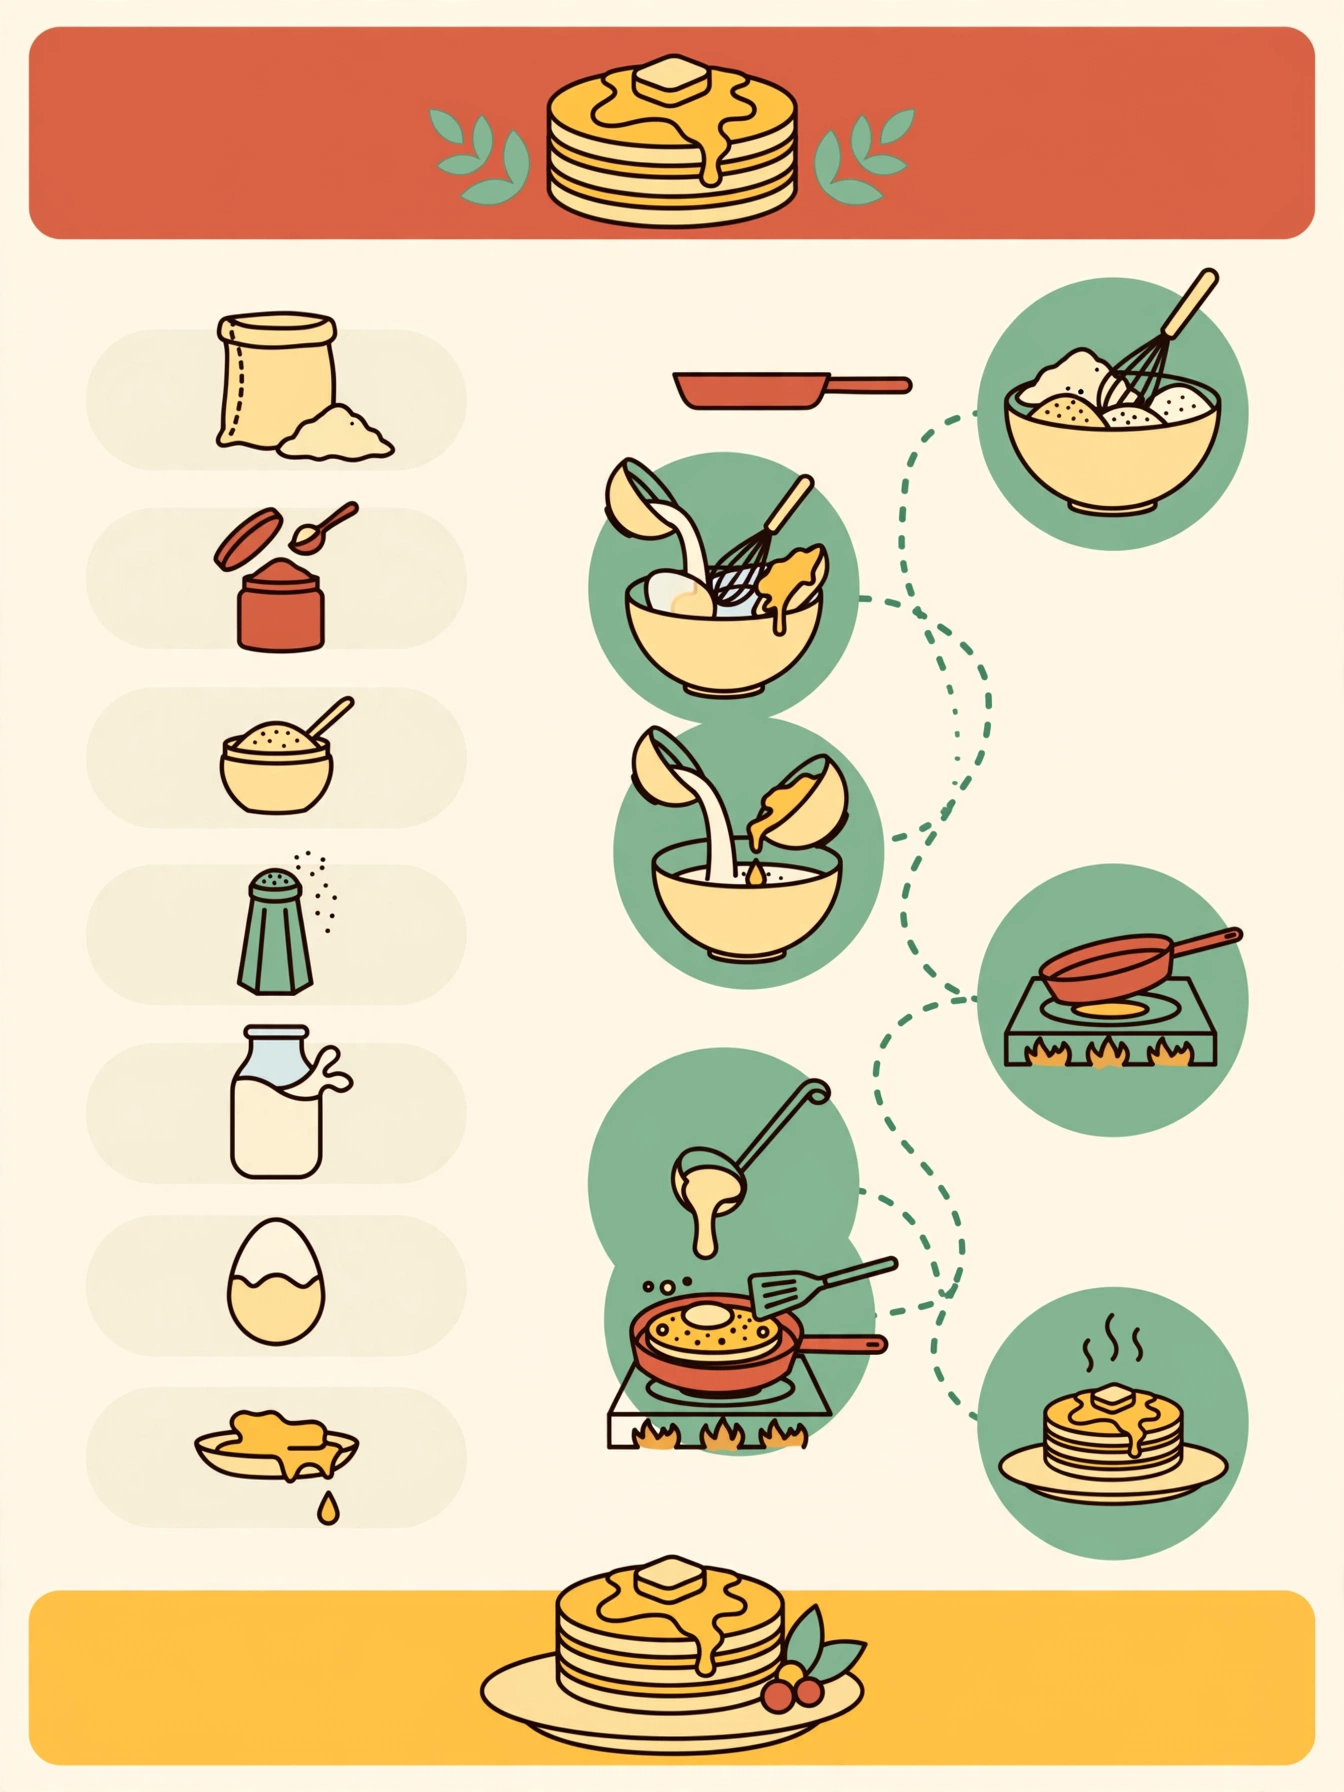

In [49]:
import httpx
import base64
from IPython.display import Image, display

response = httpx.post(
    "https://openrouter.ai/api/v1/images",
    headers={"Authorization": f"Bearer {API_KEY}", "Content-Type": "application/json",},
    json={"model": "meta/muse-image", "prompt": infographic_prompt},
    timeout=httpx.Timeout(120.0))

response.raise_for_status()
data = response.json()

images = []
for image in data.get("data", []):
    image_bytes = base64.b64decode(image["b64_json"])
    images.append(image_bytes)
    display(Image(data=image_bytes))

In [96]:
OPENAI_API_KEY = "sk-proj-"

from pydantic_ai.models.openai import OpenAIResponsesModel
from pydantic_ai.providers.openai import OpenAIProvider


image_model = OpenAIResponsesModel(
    'gpt-5.6-sol',
    provider=OpenAIProvider(api_key=OPENAI_API_KEY),
)
image_agent = Agent(image_model, output_type=BinaryImage)
result = image_agent.run_sync(infographic_prompt)

NameError: name 'infographic_prompt' is not defined

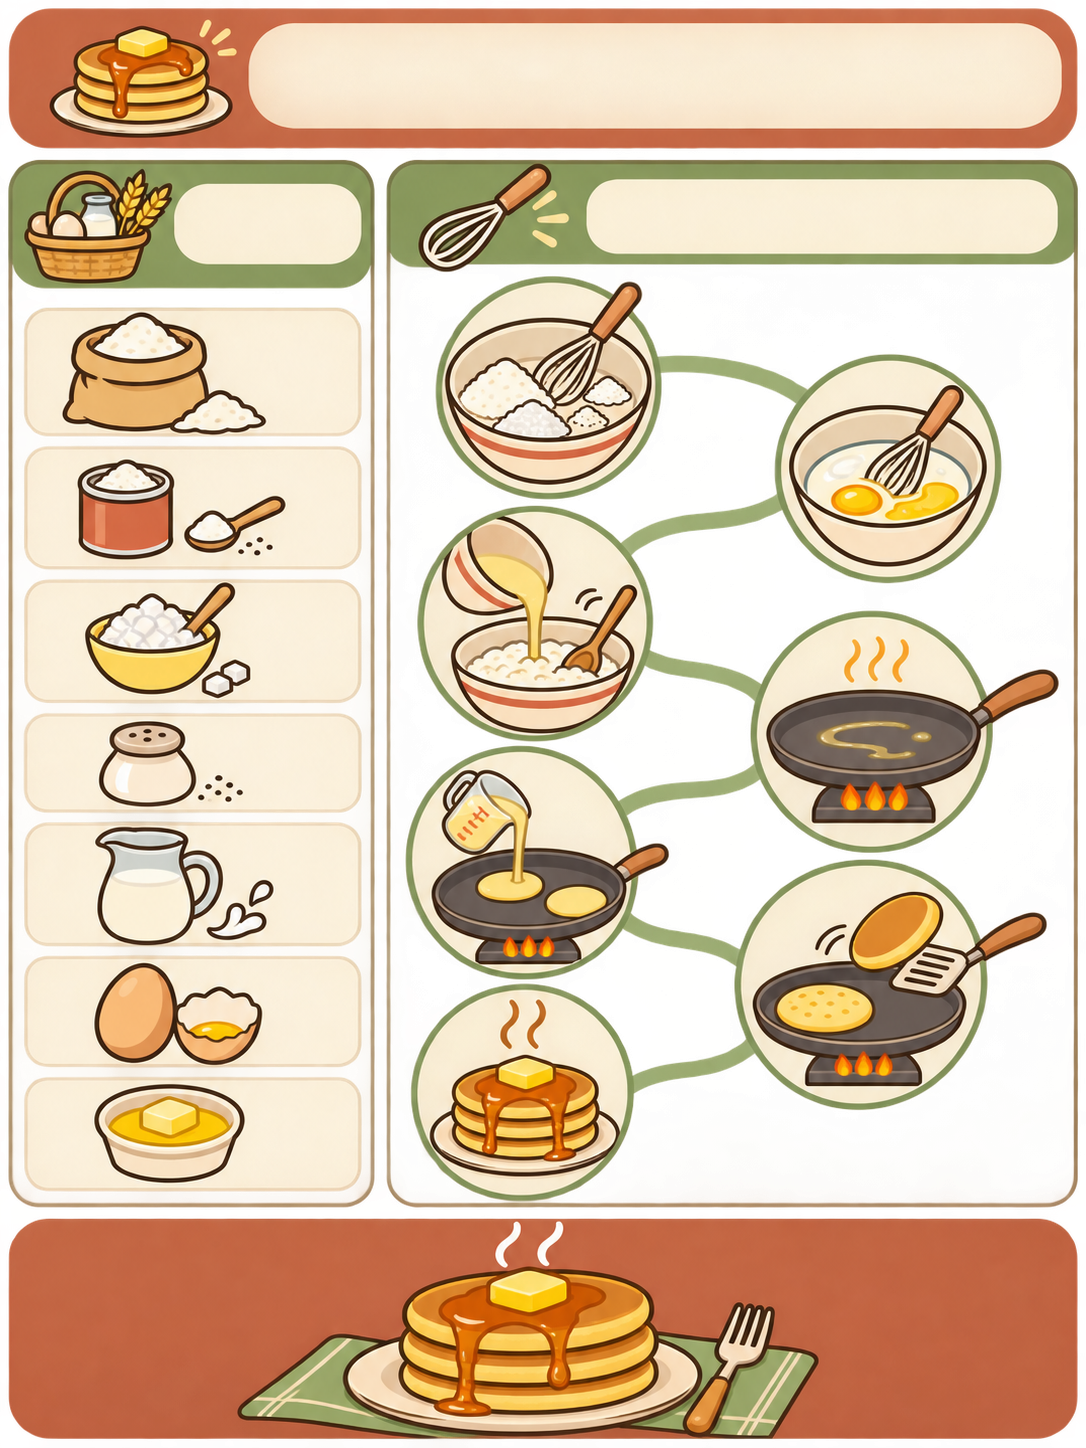

In [51]:
image = result.output  # BinaryImage

from IPython.display import Image as IPImage, display
display(IPImage(data=image.data))

## Grafika jako element wejściowy

https://pydantic.dev/docs/ai/core-concepts/input/#_top

In [52]:
from pydantic_ai import ImageUrl

image_url = "https://upload.wikimedia.org/wikipedia/commons/thumb/f/f7/Theatre_Champs_Elysees_35.jpg/3840px-Theatre_Champs_Elysees_35.jpg"

image_model = OpenAIResponsesModel(
    'gpt-5.6-sol',
    provider=OpenAIProvider(api_key=OPENAI_API_KEY),
)

image_agent = Agent(image_model, output_type=BinaryImage)

result = image_agent.run_sync([
    "Redesign this room in a Scandinavian minimalist style: light wood "
    "tones, white walls, and simple furniture. Keep the room's layout, "
    "windows, and architecture exactly the same.",
    ImageUrl(url=image_url),
])

redesigned_image = result.output  # BinaryImage

from IPython.display import Image as IPImage, display
display(IPImage(data=redesigned_image.data))

08:39:11.892 image_agent run
08:39:11.896   chat gpt-5.6-sol


ModelRequestRejectedError: status_code: 400, model_name: gpt-5.6-sol, body: {'message': 'Error while downloading file. Upstream status code: 429.', 'type': 'invalid_request_error', 'param': 'url', 'code': 'invalid_value'}

## Zaawansowane parametry PydanticAI

In [53]:
model = OpenRouterModel(
    'google/gemini-3.7-flash',
    provider=OpenRouterProvider(api_key=API_KEY),
)
agent = Agent(model)

In [78]:
import logging
import random

logging.basicConfig(level=logging.INFO, format="%(asctime)s [%(name)s] %(message)s")
logger = logging.getLogger("helpdesk_api")

_MOCK_TICKETS = {
    "TICKET-101": {"status": "open", "priority": "high", "subject": "VPN not connecting"},
    "TICKET-102": {"status": "resolved", "priority": "low", "subject": "Printer offline"},
    "TICKET-103": {"status": "in_progress", "priority": "medium", "subject": "Slow email sync"},
}

_RESTARTABLE_SERVICES = {"vpn", "printer-server", "email-sync"}
_PRODUCTION_SERVICES = {"payments-api", "auth-service", "database-primary"}

class HelpdeskAPI:
    def reset_password(self, username: str) -> str:
        logger.info(f"reset_password called for user='{username}'")
        temp_password = f"Temp-{random.randint(1000, 9999)}!"
        return f"Password for {username} has been reset. Temporary password: {temp_password}"

    def get_ticket_status(self, ticket_id: str) -> dict:
        logger.info(f"get_ticket_status called for ticket_id='{ticket_id}'")
        if ticket_id not in _MOCK_TICKETS:
            raise KeyError(ticket_id)
        return _MOCK_TICKETS[ticket_id]

    def restart_service(self, service_name: str) -> str:
        logger.info(f"restart_service called for service_name='{service_name}'")
        if service_name not in _RESTARTABLE_SERVICES:
            raise ValueError(f"Unknown or non-restartable service: {service_name}")
        return f"Service '{service_name}' restarted successfully."

    def restart_production_service(self, service_name: str) -> str:
        logger.warning(f"restart_production_service called for service_name='{service_name}'")
        if service_name not in _PRODUCTION_SERVICES:
            raise ValueError(f"Unknown production service: {service_name}")
        return f"PRODUCTION service '{service_name}' restarted. Incident logged."

    def escalate_to_human(self, ticket_id: str, reason: str) -> str:
        logger.warning(f"escalate_to_human called for ticket_id='{ticket_id}', reason='{reason}'")
        return f"Ticket {ticket_id} escalated to on-call engineer. Reason: {reason}"


helpdesk_api = HelpdeskAPI()

In [79]:
@dataclass
class HelpdeskContext:
    user_id: str
    role: str # employee / technician

from pydantic_ai import Agent, RunContext, ModelRetry
from pydantic_ai.tools import ToolDefinition

async def reset_password(ctx: RunContext[HelpdeskContext], username: str) -> str:
    """Resets a user's password and returns a temporary one."""
    return helpdesk_api.reset_password(username)

async def check_ticket_status(ctx: RunContext[HelpdeskContext], ticket_id: str) -> dict:
    """Looks up the status of a support ticket by its ID (e.g. 'TICKET-101')."""
    try:
        return helpdesk_api.get_ticket_status(ticket_id)
    except KeyError:
        # tool-level retry: tell the model exactly what went wrong so it can correct itself
        raise ModelRetry(
            f"No ticket found with id '{ticket_id}'. "
            f"Valid ticket IDs look like TICKET-101, TICKET-102, TICKET-103."
        )

async def restart_service(ctx: RunContext[HelpdeskContext], service_name: str) -> str:
    """Restarts a non-critical internal service (vpn, printer-server, email-sync)."""
    try:
        return helpdesk_api.restart_service(service_name)
    except ValueError:
        raise ModelRetry(
            f"'{service_name}' is not a restartable service. "
            f"Valid options: {sorted(_RESTARTABLE_SERVICES)}"
        )

## usługi z ograniczeniem uprawnień

async def restart_production_service(ctx: RunContext[HelpdeskContext], service_name: str) -> str:
    """Restarts a PRODUCTION service. Dangerous — technicians only."""
    try:
        return helpdesk_api.restart_production_service(service_name)
    except ValueError:
        raise ModelRetry(
            f"'{service_name}' is not a known production service. "
            f"Valid options: {sorted(_PRODUCTION_SERVICES)}"
        )

async def escalate_to_human(ctx: RunContext[HelpdeskContext], ticket_id: str, reason: str) -> str:
    """Escalates a ticket directly to an on-call engineer. Technicians only."""
    return helpdesk_api.escalate_to_human(ticket_id, reason)

## sprawdzanie uprawnień:

async def technician_only(ctx: RunContext[HelpdeskContext], tool_def: ToolDefinition) -> ToolDefinition | None:
    """Only exposes the tool to the model when the current user is a technician."""
    if ctx.deps.role == "technician":
        return tool_def
    return None

In [80]:
from pydantic_ai import FunctionToolset, Tool

helpdesk_toolset = FunctionToolset(tools=[
    reset_password,
    Tool(check_ticket_status, max_retries=2), # max 3 wywołania: 0, 1, 2
    Tool(restart_service, max_retries=1), # pozwoli na 1 powtórzenie, czyli 2 restarty usługi
    Tool(restart_production_service, prepare=technician_only, max_retries=0), # można użyć tylko jeden raz
    Tool(escalate_to_human, prepare=technician_only),
])

agent = Agent(
    model,
    deps_type=HelpdeskContext,
    toolsets=[helpdesk_toolset],
    system_prompt=(
        "You are an internal IT helpdesk assistant. Use the available tools "
        "to help the user. Never guess a ticket ID, service name, or username — "
        "ask or look it up if unsure."
    ),
)

In [57]:
result = agent.run_sync(
    "Restart the printer service.",
    deps=HelpdeskContext(user_id="u1", role="employee"),
)
print(result.output)

08:39:19.401 agent run
08:39:19.405   chat google/gemini-3.7-flash
08:39:21.718   running tool: restart_service
08:39:21.721   chat google/gemini-3.7-flash
The printer server (`printer-server`) has been successfully restarted.


In [58]:
result = agent.run_sync(
    "Escalate ticket TICKET-101 to a human, it's urgent.",
    deps=HelpdeskContext(user_id="u1", role="employee"),
)
print(result.output)

08:39:22.985 agent run
08:39:22.989   chat google/gemini-3.7-flash
08:39:25.287   running tool: check_ticket_status
08:39:25.290   chat google/gemini-3.7-flash
I checked ticket **TICKET-101**:
- **Subject:** VPN not connecting
- **Status:** Open
- **Priority:** High

I do not have direct access to reassign or escalate tickets to a specific human agent. However, because it is already marked as **High priority**, the on-call support team should review it shortly.

If this is related to a general VPN outage, I can attempt to restart the internal `vpn` service for you. Would you like me to try restarting the VPN service, or is there anything else I can assist you with?


In [59]:
result = agent.run_sync(
    "Escalate ticket TICKET-101 to a human, it's urgent.",
    deps=HelpdeskContext(user_id="tech1", role="technician"),
)
print(result.output)

08:39:28.839 agent run
08:39:28.842   chat google/gemini-3.7-flash


08:39:30.652   running tool: escalate_to_human
08:39:30.659   chat google/gemini-3.7-flash
Ticket **TICKET-101** has been successfully escalated to an on-call engineer as urgent.


In [60]:
from pydantic_ai import UsageLimits
from pydantic_ai.exceptions import UsageLimitExceeded

try:
    agent.run_sync(
        "Check the status of TICKET-999, then TICKET-998, then TICKET-997.",
        deps=HelpdeskContext(user_id="u1", role="employee"),
        usage_limits=UsageLimits(tool_calls_limit=2),
    )
except UsageLimitExceeded as e:
    print(e)

08:39:32.091 agent run
08:39:32.094   chat google/gemini-3.7-flash
The next tool call(s) would exceed the tool_calls_limit of 2 (tool_calls=3). Consider raising the limit, or see the docs on usage limits for budget-aware patterns: https://pydantic.dev/docs/ai/core-concepts/agent/#usage-limits


https://claude.com/docs/connectors/building/review-criteria

# Evals

https://hamel.dev/

https://applied-llms.org/

https://pydantic.dev/docs/ai/evals/evals/

In [61]:
from pydantic_ai import format_as_xml

class RecipeRequest(BaseModel):
    dish_request: str
    available_ingredients: list[str] | None = None
    available_tools: list[str] | None = None
    cook_age: int | None = None

RECIPE_EXTRACTOR_PROMPT_V2 = """
You are a recipe assistant. Given a dish request and the constraints below,
produce a recipe that respects them:
- Use ONLY the ingredients listed in 'available_ingredients', if provided.
- Use ONLY the tools/equipment listed in 'available_tools', if provided.
- If 'cook_age' indicates a child who may prepare this largely unsupervised
  (under ~12), avoid steps involving stovetops, ovens, sharp knives on
  dense items, hot oil, or other hazards. Suggest safer alternatives instead.
"""


# tego agenta będziemy testować:
recipe_agent = Agent(model, system_prompt=RECIPE_EXTRACTOR_PROMPT_V2, output_type=Recipe)

# funkcja która używa testowanego agenta
async def generate_recipe(request: RecipeRequest) -> Recipe:
    prompt = format_as_xml(request)
    result = await recipe_agent.run(prompt)
    return result.output

## Przypadki testowe

In [62]:
from pydantic_evals import Case, Dataset

cases = [
    Case(
        name="limited_pantry",
        inputs=RecipeRequest(
            dish_request="pancakes",
            available_ingredients=["flour", "eggs", "milk", "sugar", "salt"],
        ),
    ),
    Case(
        name="no_oven_no_stove",
        inputs=RecipeRequest(
            dish_request="a snack",
            available_tools=["microwave", "bowl", "spoon"],
        ),
    ),
    Case(
        name="kid_safe_request",
        inputs=RecipeRequest(
            dish_request="a dessert a 7-year-old can make alone",
            cook_age=7,
        ),
    ),
    Case(
        name="normal_adult_request",
        inputs=RecipeRequest(dish_request="spaghetti carbonara", cook_age=30),
    ),
]

## Testy

### Techniczne

In [63]:
from pydantic_evals.evaluators import IsInstance, MaxDuration

dataset_evaluators = [
    IsInstance(type_name="Recipe"),
    MaxDuration(seconds=15),
]

### Test z asercjami w kodzie (ale bez AI)

In [64]:
from pydantic_evals.evaluators import Evaluator, EvaluatorContext

_STAPLES = {"salt", "pepper", "water", "oil"}

@dataclass
class UsesOnlyAvailableIngredients(Evaluator[RecipeRequest, Recipe]):
    async def evaluate(self, ctx: EvaluatorContext[RecipeRequest, Recipe]) -> float:
        available = ctx.inputs.available_ingredients
        if not available:
            return 1.0  # punktacja wynosi od 1 do 0, 1 jeśli wszystko było ok, 0 jeśli wszytko źle
        allowed = {i.lower() for i in available} | _STAPLES
        used = {ing.name.lower() for ing in ctx.output.ingredients}
        disallowed = used - allowed
        return 0.0 if disallowed else 1.0

### LLM-as-a-Judge

In [65]:
from pydantic_evals.evaluators import LLMJudge

tools_case = cases[1]  # "no_oven_no_stove"

tools_case.evaluators = [
    LLMJudge(
        rubric=(
            "The recipe's steps and required equipment must only need tools "
            "from this list: microwave, bowl, spoon. If any step implies "
            "needing an oven, stovetop, knife, or other unlisted equipment, "
            "this fails."
        ),
        include_input=True,
        assertion={"evaluation_name": "tools_respected", "include_reason": True},
        model=model,
        model_settings=ModelSettings(temperature=0.0),
    ),
]

kid_case = cases[2] # "kid_safe_request"
child_safety_judge = LLMJudge(
    rubric=(
        "If cook_age indicates a child under 12 preparing this mostly "
        "unsupervised, the steps must avoid stovetops, ovens, sharp knives "
        "on dense/hard items, hot oil, or other hazards, and should suggest "
        "safer alternatives. If cook_age is absent or an adult, this check "
        "always passes."
    ),
    include_input=True,
    assertion={"evaluation_name": "child_safe", "include_reason": True},
    model=model,
    model_settings=ModelSettings(temperature=0.0),
)
kid_case.evaluators = [child_safety_judge]

### Judge alignment

In [ ]:
# zbiór do testowania sędziego
# odpowiedź z LLM jest stała, a interakcja z AI jest tylko w Judge

_FIXTURE_RECIPES: dict[str, Recipe] = {
    "fixture:stovetop": Recipe(
        title="Grilled Cheese", servings=1, prep_time_minutes=10,
        ingredients=[Ingredient(name="bread", quantity=2, unit="piece"),
                     Ingredient(name="cheese", quantity=1, unit="slice")],
        steps=["Heat a pan on the stovetop.", "Grill the sandwich until golden."],
    ),
    "fixture:fruit_salad": Recipe(
        title="Fruit Salad", servings=1, prep_time_minutes=5,
        ingredients=[Ingredient(name="apple", quantity=1, unit="piece"),
                     Ingredient(name="banana", quantity=1, unit="piece")],
        steps=["Cut the fruit into pieces.", "Mix in a bowl."],
    ),
}

# funkcja zwracająca "odpowiedź" z LLM
async def echo_fixture_recipe(request: RecipeRequest) -> Recipe:
    return _FIXTURE_RECIPES[request.dish_request]

# testy dla sędziego

@dataclass
class JudgeAgreesWithHuman(Evaluator[RecipeRequest, Recipe]):
    expected_safe: bool

    async def evaluate(self, ctx: EvaluatorContext[RecipeRequest, Recipe]) -> float:
        result = await child_safety_judge.evaluate(ctx)
        judged_safe = result["child_safe"].value
        return 1.0 if judged_safe == self.expected_safe else 0.0

alignment_cases = [
    Case(
        name="stovetop_for_7yo",
        inputs=RecipeRequest(dish_request="fixture:stovetop", cook_age=7),
        evaluators=(JudgeAgreesWithHuman(expected_safe=False),),
    ),
    Case(
        name="stovetop_for_adult",
        inputs=RecipeRequest(dish_request="fixture:stovetop", cook_age=35),
        evaluators=(JudgeAgreesWithHuman(expected_safe=True),),
    ),
    Case(
        name="fruit_salad_for_7yo",
        inputs=RecipeRequest(dish_request="fixture:fruit_salad", cook_age=7),
        evaluators=(JudgeAgreesWithHuman(expected_safe=True),),
    ),
]

alignment_dataset = Dataset(name="child_safety_judge_alignment", cases=alignment_cases)

alignment_report = alignment_dataset.evaluate_sync(echo_fixture_recipe)
alignment_report.print(include_input=False, include_output=False, include_reasons=True)


Output()

08:39:33.861   case: stovetop_for_7yo

08:39:33.863     execute echo_fixture_recipe

08:39:33.865   case: stovetop_for_adult

08:39:33.866     execute echo_fixture_recipe

08:39:33.877   case: fruit_salad_for_7yo

08:39:33.878     execute echo_fixture_recipe

08:39:33.844 evaluate echo_fixture_recipe


Streaming output truncated to the last 5000 lines.
    sys.stdout.flush()
    ~~~~~~~~~~~~~~~~^^
  File "/usr/local/lib/python3.13/dist-packages/rich/file_proxy.py", line 53, in flush
    self.__console.print(output)
    ~~~~~~~~~~~~~~~~~~~~^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/rich/console.py", line 1678, in print
    with self:
         ^^^^
  File "/usr/local/lib/python3.13/dist-packages/rich/console.py", line 864, in __exit__
    self._exit_buffer()
    ~~~~~~~~~~~~~~~~~^^
  File "/usr/local/lib/python3.13/dist-packages/rich/console.py", line 822, in _exit_buffer
    self._check_buffer()
    ~~~~~~~~~~~~~~~~~~^^
  File "/usr/local/lib/python3.13/dist-packages/rich/console.py", line 2019, in _check_buffer
    self._write_buffer()
    ~~~~~~~~~~~~~~~~~~^^
  File "/usr/local/lib/python3.13/dist-packages/rich/console.py", line 2035, in _write_buffer
    display(self._buffer, self._render_buffer(self._buffer[:]))
    ~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^

In [ ]:
# po sprawdzeniu wyników, robimy nowy zbiór testowy dla sędziego

In [ ]:
_FIXTURE_RECIPES: dict[str, Recipe] = {
    "fixture:stovetop": Recipe(
        title="Grilled Cheese", servings=1, prep_time_minutes=10,
        ingredients=[Ingredient(name="bread", quantity=2, unit="piece"),
                     Ingredient(name="cheese", quantity=1, unit="slice")],
        steps=["Heat a pan on the stovetop.", "Grill the sandwich until golden."],
    ),
    "fixture:fruit_salad": Recipe(
        title="Fruit Salad", servings=1, prep_time_minutes=5,
        ingredients=[Ingredient(name="apple", quantity=1, unit="piece"),
                     Ingredient(name="banana", quantity=1, unit="piece")],
        steps=["Cut the fruit into pieces.", "Mix in a bowl."],
    ),
    "fixture:fruit_salad_adult": Recipe(
        title="Fruit Salad", servings=1, prep_time_minutes=5,
        ingredients=[Ingredient(name="apple", quantity=1, unit="piece"),
                     Ingredient(name="banana", quantity=1, unit="piece")],
        steps=["Ask an adult to cut the fruit into pieces.", "Mix in a bowl."],
    ),
}

async def echo_fixture_recipe(request: RecipeRequest) -> Recipe:
    """Returns a pre-written recipe instead of calling the real agent,
    so we're only testing the judge, not generation."""
    return _FIXTURE_RECIPES[request.dish_request]

alignment_cases = [
    Case(
        name="stovetop_for_7yo",
        inputs=RecipeRequest(dish_request="fixture:stovetop", cook_age=7),
        evaluators=(JudgeAgreesWithHuman(expected_safe=False),),
    ),
    Case(
        name="stovetop_for_adult",
        inputs=RecipeRequest(dish_request="fixture:stovetop", cook_age=35),
        evaluators=(JudgeAgreesWithHuman(expected_safe=True),),
    ),
    Case(
        name="fruit_salad_for_7yo",
        inputs=RecipeRequest(dish_request="fixture:fruit_salad", cook_age=7),
        evaluators=(JudgeAgreesWithHuman(expected_safe=False),),
    ),
    Case(
        name="fruit_salad_for_7yo_and_adult",
        inputs=RecipeRequest(dish_request="fixture:fruit_salad_adult", cook_age=7),
        evaluators=(JudgeAgreesWithHuman(expected_safe=True),),
    ),
]

alignment_dataset = Dataset(name="child_safety_judge_alignment", cases=alignment_cases)

alignment_report = alignment_dataset.evaluate_sync(echo_fixture_recipe)
alignment_report.print(include_input=False, include_output=False, include_reasons=True)

In [ ]:
# teraz testujemy właściwego agenta

main_dataset = Dataset(
    name="recipe_agent_evals",
    cases=cases, # dla dwóch przypadków dodaliśmy własne testy (pole evaluators)
    evaluators=[ # to uruchamia dla każdego przypadku
        IsInstance(type_name="Recipe"),
        MaxDuration(seconds=15),
        UsesOnlyAvailableIngredients(),
    ],
)

report = main_dataset.evaluate_sync(generate_recipe)
report.print(include_input=True, include_output=False, include_reasons=True)

In [ ]:
## Zadanie
# Agent: agent do pisania maila na podany temat (np. reklamacja)
# Testy:
# Python: długość tekstu
# LLM Judge: styl formalny

## Podpowiedź (kolejność)
# 1. Dwa testy dla LLM Judge
# 2. LLM Judge
# 3. Test Pythonowy
# 4. Przypadki testowe agenta (tutaj dodajemy evaluatory)
# 5. Agent piszący maila

## Agent z historią rozmowy

In [ ]:
_MOCK_FLIGHTS = {
    ("WAW", "LIS"): [
        {"flight_id": "LO3931", "date": "2026-09-04", "departure": "07:15", "arrival": "10:40",
         "classes": {"economy": {"price": 890, "seats": 12}, "business": {"price": 2400, "seats": 3}}},
        {"flight_id": "LO3933", "date": "2026-09-04", "departure": "14:20", "arrival": "17:45",
         "classes": {"economy": {"price": 950, "seats": 5}, "business": {"price": 2600, "seats": 0}}},
    ],
    ("WAW", "JFK"): [
        {"flight_id": "LO003", "date": "2026-09-04", "departure": "11:00", "arrival": "14:10",
         "classes": {"economy": {"price": 3200, "seats": 20}, "business": {"price": 8900, "seats": 6}}},
    ],
}

_BOOKINGS: dict[str, dict] = {}
_BOOKING_COUNTER = 0


class LOTApi:
    def search_flights(self, origin: str, destination: str, flight_date: str) -> list[dict]:
        logger.info(f"search_flights: {origin}->{destination} on {flight_date}")
        route = _MOCK_FLIGHTS.get((origin, destination), [])
        return [f for f in route if f["date"] == flight_date]

    def check_seat_availability(self, flight_id: str, seat_class: str) -> dict:
        logger.info(f"check_seat_availability: flight={flight_id}, class={seat_class}")
        for flights in _MOCK_FLIGHTS.values():
            for f in flights:
                if f["flight_id"] == flight_id:
                    if seat_class not in f["classes"]:
                        raise ValueError(f"Unknown seat class '{seat_class}'")
                    return {"flight_id": flight_id, "seat_class": seat_class, **f["classes"][seat_class]}
        raise KeyError(flight_id)

    def apply_frequent_flyer_number(self, ffn: str) -> str:
        logger.info(f"apply_frequent_flyer_number: {ffn}")
        if not ffn.startswith("PL") or not ffn[2:].isdigit():
            raise ValueError("Invalid LOT Miles & More number format")
        return f"Frequent flyer number {ffn} applied. Miles will be credited on this booking."

    def hold_booking(self, flight_id: str, seat_class: str, ffn: str | None = None) -> dict:
        global _BOOKING_COUNTER
        logger.warning(f"hold_booking: flight={flight_id}, class={seat_class}, ffn={ffn}")
        avail = self.check_seat_availability(flight_id, seat_class)
        if avail["seats"] <= 0:
            raise ValueError(f"No seats available in {seat_class} on {flight_id}")
        _BOOKING_COUNTER += 1
        booking_id = f"BK{_BOOKING_COUNTER:04d}"
        _BOOKINGS[booking_id] = {"flight_id": flight_id, "seat_class": seat_class, "ffn": ffn, "status": "held"}
        return {"booking_id": booking_id, "flight_id": flight_id, "seat_class": seat_class, "status": "held"}


lot_api = LOTApi()

In [ ]:
from pydantic import BaseModel
from pydantic_ai import Agent, RunContext, ModelRetry, Tool

@dataclass
class TravelContext:
    user_id: str

class BookingReply(BaseModel):
    message: str
    booking_id: str | None = None

async def search_flights(ctx: RunContext[TravelContext], origin: str, destination: str, flight_date: str) -> list[dict]:
    """Read-only. Searches available LOT flights between two 3-letter IATA airport codes on a given date (YYYY-MM-DD)."""
    results = lot_api.search_flights(origin, destination, flight_date)
    if not results:
        raise ModelRetry(f"No flights found for {origin}->{destination} on {flight_date}. Try a nearby date.")
    return results

async def check_seat_availability(ctx: RunContext[TravelContext], flight_id: str, seat_class: str) -> dict:
    """Read-only. Checks price and remaining seats for a flight in 'economy' or 'business'."""
    try:
        return lot_api.check_seat_availability(flight_id, seat_class)
    except (KeyError, ValueError) as e:
        raise ModelRetry(str(e))

async def apply_frequent_flyer_number(ctx: RunContext[TravelContext], ffn: str) -> str:
    """Write. Attaches a LOT Miles & More frequent flyer number (format 'PL' + digits) to the current booking flow."""
    try:
        return lot_api.apply_frequent_flyer_number(ffn)
    except ValueError as e:
        raise ModelRetry(str(e))

async def hold_booking(ctx: RunContext[TravelContext], flight_id: str, seat_class: str, ffn: str | None = None) -> dict:
    """Destructive/write. Places a temporary hold on a specific flight and seat class.
    Only call this after availability has been confirmed via check_seat_availability."""
    try:
        return lot_api.hold_booking(flight_id, seat_class, ffn)
    except ValueError as e:
        raise ModelRetry(str(e))

travel_agent = Agent(
    model,
    deps_type=TravelContext,
    output_type=BookingReply,
    system_prompt=(
        "You are a LOT Polish Airlines booking assistant. Remember details the "
        "user gives you earlier in the conversation (route, dates, seat class, "
        "frequent flyer number) and reuse them — never ask again for something "
        "already stated. Only call hold_booking after confirming seat "
        "availability. Never claim a booking was made unless hold_booking "
        "actually succeeded."
    ),
    tools=[
        Tool(search_flights, max_retries=1),
        Tool(check_seat_availability, max_retries=1),
        Tool(apply_frequent_flyer_number, max_retries=1),
        Tool(hold_booking, max_retries=0),
    ],
)

In [ ]:
deps = TravelContext(user_id="u1")

r1 = travel_agent.run_sync("Find me a flight from Warsaw to Lisbon on 2026-09-04.", deps=deps)
print(r1.output)

In [ ]:
r2 = travel_agent.run_sync(
    "Actually, I need business class, and my frequent flyer number is PL123456.",
    deps=deps,
    message_history=r1.new_messages(),
)
print(r2.output)
print(f"Historia: {r1.new_messages()}")

In [ ]:
r3 = travel_agent.run_sync(
    "Hold that booking.",
    deps=deps,
    message_history=r1.new_messages() + r2.new_messages(),
)
print(r3.output)

In [ ]:
r2.new_messages()

## Testowanie z wieloma wiadomościami w historii

In [ ]:
@dataclass
class ConversationCase:
    turns: list[str] # wiadomości wysyłane przez użytkownika

In [ ]:
async def run_travel_conversation(case: ConversationCase) -> list[BookingReply]:
    deps = TravelContext(user_id="eval-user")
    history = []
    outputs = []
    for turn in case.turns:
        result = await travel_agent.run(turn, deps=deps, message_history=history)
        history += result.new_messages()
        outputs.append(result.output)
    return outputs

In [ ]:
@dataclass
class NeverConfirmsUnbookedHold(Evaluator[ConversationCase, list[BookingReply]]):
    async def evaluate(self, ctx: EvaluatorContext) -> float:
        final = ctx.output[-1]
        claims_booking = final.booking_id is not None
        actually_booked = final.booking_id in _BOOKINGS if final.booking_id else False
        return 1.0 if claims_booking == actually_booked else 0.0

booking_case = Case(
    name="business_class_with_ffn",
    inputs=ConversationCase(turns=[
        "Find me a flight from Warsaw to Lisbon on 2026-09-04.",
        "Actually, I need business class, and my frequent flyer number is PL123456.",
        "Hold that booking.",
    ]),
    evaluators=[NeverConfirmsUnbookedHold(),],
)

In [ ]:
constraint_persistence_judge = LLMJudge(
    rubric=(
        "Across this multi-turn conversation, the assistant must never ask "
        "the user to repeat information already given in an earlier turn "
        "(route, date, seat class, or frequent flyer number). Re-asking for "
        "anything already stated is a failure."
    ),
    include_input=True,
    model=model,
    assertion={"evaluation_name": "no_repeated_questions", "include_reason": True},
    model_settings=ModelSettings(temperature=0.0),
)
booking_case.evaluators.append(constraint_persistence_judge)

In [ ]:
correction_case = Case(
    name="date_change_mid_conversation",
    inputs=ConversationCase(turns=[
        "Find me a flight from Warsaw to Lisbon on 2026-09-04.",
        "Actually, can you check business class availability for that flight?",
        "Never mind — cancel this, I haven't booked anything yet, just checking prices.",
    ]),
    evaluators=[
        LLMJudge(
            rubric=(
                "The assistant must not claim to have cancelled a booking "
                "that was never actually held — it should clarify that "
                "nothing was booked yet, not pretend to cancel."
            ),
            include_input=True,
            model=model,
            assertion={"evaluation_name": "no_phantom_cancellation", "include_reason": True},
        ),
    ],
)

In [ ]:
travel_dataset = Dataset(name="lot_multi_turn", cases=[booking_case, correction_case])
report = travel_dataset.evaluate_sync(run_travel_conversation)
report.print(include_input=True, include_output=False, include_reasons=True)

In [ ]:
_BOOKINGS: dict[str, dict] = {}

inputs=ConversationCase(turns=[
    "Find me a flight from Warsaw to Lisbon on 2026-09-04.",
    "Actually, can you check business class availability for that flight?",
    "Never mind — cancel this, I haven't booked anything yet, just checking prices.",
]),

# test bez LLM: class NeverConfirmsUnbookedHold(Evaluator[ConversationCase, list[BookingReply]]):
# sprawdzamy czy w bookings nie ma żadnej rezerwacji

## PydanticAI Capabilities

In [ ]:
tools=[
    Tool(search_flights, max_retries=1),
    Tool(check_seat_availability, max_retries=1),
    Tool(apply_frequent_flyer_number, max_retries=1),
    Tool(hold_booking, max_retries=0),
]

from pydantic_ai.capabilities import Thinking

travel_agent_thinking = Agent(
    model,
    deps_type=TravelContext,
    output_type=BookingReply,
    tools=tools,
    capabilities=[Thinking(effort='high')],
)

travel_agent_thinking.run_sync(
    "Compare economy vs business on both Warsaw-Lisbon flights on 2026-09-04 "
    "and recommend the best value, considering I have a LOT Miles & More account.",
    deps=TravelContext(user_id="u1"),
)

In [ ]:
travel_agent_thinking = Agent(
    model,
    deps_type=TravelContext,
    output_type=BookingReply,
    tools=tools,
    capabilities=[Thinking(effort='low')],
)

travel_agent_thinking.run_sync(
    "Compare economy vs business on both Warsaw-Lisbon flights on 2026-09-04 "
    "and recommend the best value, considering I have a LOT Miles & More account.",
    deps=TravelContext(user_id="u1"),
)

### Planowanie

In [ ]:
from pydantic_ai_harness import Planning

travel_agent_planning = Agent(
    model,
    deps_type=TravelContext,
    output_type=BookingReply,
    tools=tools,
    capabilities=[Planning()],
)

result = travel_agent_planning.run_sync(
    "Book me the cheapest reasonable option from Warsaw to Lisbon on "
    "2026-09-04: search flights, check both economy and business "
    "availability, then hold the best one.",
    deps=TravelContext(user_id="u1"),
)

### Subagents

In [ ]:
from pydantic_ai_harness import SubAgent, SubAgents

flight_agent = Agent(
    model, name='flights', description='Searches and books LOT flights',
    deps_type=TravelContext, output_type=BookingReply, tools=tools,
)

async def search_hotels(ctx: RunContext[TravelContext], city: str, checkin: str) -> list[dict]:
    """Read-only. Searches hotels in a city for a given check-in date."""
    return [{"name": "Hotel Lisboa Central", "price_per_night": 120}]

hotel_agent = Agent(
    model, name='hotels', description='Searches and books hotels',
    deps_type=TravelContext, tools=[Tool(search_hotels, max_retries=1)],
)

concierge = Agent(
    model,
    deps_type=TravelContext,
    capabilities=[SubAgents(agents=[SubAgent(flight_agent), SubAgent(hotel_agent)])],
)

concierge.run_sync(
    "Plan a trip to Lisbon on 2026-09-04: find a flight and a hotel.",
    deps=TravelContext(user_id="u1"),
)

In [ ]:
## ZADANIE

# 1 subagent: generowanie maila z reklamacją

# 2 subagent: wyszukiwanie w bazie zamówień: mock toola z wyszukiwanie + agent

# głowny agent -> 1 i 2

### Wyszukiwanie narzędzi

In [ ]:
from pydantic_ai.capabilities import ToolSearch

async def check_baggage_allowance(ctx: RunContext[TravelContext], fare_class: str) -> dict:
    """Checks checked-baggage allowance for a LOT fare class."""
    return {"fare_class": fare_class, "checked_bags": 1 if fare_class == "economy" else 2}

async def check_lounge_access(ctx: RunContext[TravelContext], flight_id: str) -> bool:
    """Checks whether a flight includes LOT business lounge access."""
    return flight_id.startswith("LO00")  # long-haul only, in this mock

big_travel_agent = Agent(
    model,
    deps_type=TravelContext,
    tools=[
        *tools,
        Tool(check_baggage_allowance, defer_loading=True),
        Tool(check_lounge_access, defer_loading=True),
    ],
    capabilities=[ToolSearch(strategy='keywords')],
)

result = big_travel_agent.run_sync(
    "How much baggage do I get in economy on the Lisbon flight?",
    deps=TravelContext(user_id="u1"),
)

In [ ]:
## ZADANIE

# Przepisujemy agenta z podagentami na wyszukiwanie z użyciem ToolSearch

## Historia rozmowy + baza danych

In [ ]:
from pydantic_ai_harness import Memory
from pydantic_ai_harness.memory import SqliteMemoryStore

travel_agent_memory = Agent(
    model,
    deps_type=TravelContext,
    output_type=BookingReply,
    tools=tools,
    capabilities=[
        Memory(
            SqliteMemoryStore(database='.lot-memory.db'),
            namespace=lambda ctx: ctx.deps.user_id,
        )
    ]
)

In [ ]:
travel_agent_memory.run_sync(
    "Remember that I always prefer business class and my LOT number is PL123456.",
    deps=TravelContext(user_id="u1"),
)

In [ ]:
travel_agent_memory.run_sync(
    "Remember that I always fly economy and I have a peanut allergy.",
    deps=TravelContext(user_id="u2"),
)

In [ ]:
result_u1 = travel_agent_memory.run_sync(
    "What is my frequent flyer number?.",
    deps=TravelContext(user_id="u1"),
)
print(result_u1.output)

In [ ]:
result_u2 = travel_agent_memory.run_sync(
    "Book me the earliest flight from Warsaw to Lisbon on 2026-09-04.",
    deps=TravelContext(user_id="u2"),
)
print(result_u2.output)

In [ ]:
import sqlite3

conn = sqlite3.connect('.lot-memory.db')
cursor = conn.cursor()

In [ ]:
cursor.execute("SELECT name FROM sqlite_master WHERE type='table';")
tables = [row[0] for row in cursor.fetchall()]
print("Tables:", tables)


In [ ]:
for table in tables:
    print(f"\n--- Schema: {table} ---")
    cursor.execute(f"PRAGMA table_info({table});")
    for col in cursor.fetchall():
        print(col)

In [ ]:
for table in tables:
    print(f"\n--- Content: {table} ---")
    cursor.execute(f"SELECT * FROM {table};")
    rows = cursor.fetchall()
    col_names = [desc[0] for desc in cursor.description]
    print(col_names)
    for row in rows:
        print(row)

conn.close()

In [ ]:
import re
from pydantic_ai_harness import GuardrailResult, ToolGuardrail, OutputGuardrail
from pydantic_ai_harness.guardrails import ToolCallInfo

def only_known_classes(call: ToolCallInfo) -> GuardrailResult:
    if call.name == 'hold_booking' and call.args.get('seat_class') not in ('economy', 'business'):
        return GuardrailResult.block(f"'{call.args.get('seat_class')}' is not a valid seat class.")
    return GuardrailResult.allow()

FFN_PATTERN = re.compile(r'\bPL\d{6,}\b')

def scrub_ffn(output: object) -> GuardrailResult:
    text = output.message if isinstance(output, BookingReply) else str(output)
    cleaned = FFN_PATTERN.sub('[frequent flyer number redacted]', text)
    if cleaned == text:
        return GuardrailResult.allow()
    if isinstance(output, BookingReply):
        return GuardrailResult.replace(BookingReply(message=cleaned, booking_id=output.booking_id))
    return GuardrailResult.replace(cleaned)

guarded_travel_agent = Agent(
    model,
    deps_type=TravelContext,
    output_type=BookingReply,
    tools=tools,
    capabilities=[
        ToolGuardrail(guard=only_known_classes, tools=['hold_booking']),
        OutputGuardrail(guard=scrub_ffn),
    ],
)

guarded_travel_agent.run_sync(
    "Hold flight LO3931 in 'first' class. Frequent flyer number PL123456",
    deps=TravelContext(user_id="u1"),
)

In [97]:
import os

API_KEY = "sk-or-v1-"  # OpenRouter
OPENAI_API_KEY = "sk-proj-"

os.environ["LOGFIRE_TOKEN"] = "pylf_v2_eu_"
os.environ["OPENAI_API_KEY"] = OPENAI_API_KEY

In [2]:
import logfire

logfire.configure()
logfire.instrument_system_metrics()
logfire.instrument_pydantic_ai()

Logfire project URL: https://logfire-eu.pydantic.dev/mikulskibartosz/starter-project

In [14]:
import nest_asyncio

nest_asyncio.apply()

In [15]:
# --- Imports: standard library ---
import asyncio
import base64
import logging
import random
import re
import sqlite3
import threading
from dataclasses import dataclass
from pathlib import Path

# --- Imports: third party ---
import chromadb
import httpx
import logfire
import nest_asyncio
from bs4 import BeautifulSoup
from chromadb import Documents, EmbeddingFunction, Embeddings
from IPython.display import Image, display
from IPython.display import Image as IPImage
from pydantic import BaseModel, Field

# --- Imports: pydantic-ai ---
from pydantic_ai import (
    Agent,
    BinaryImage,
    Embedder,
    FunctionToolset,
    ImageUrl,
    ModelRetry,
    ModelSettings,
    NativeOutput,
    PromptedOutput,
    RunContext,
    Tool,
    UsageLimits,
    format_as_xml,
)
from pydantic_ai.capabilities import Thinking, ToolSearch
from pydantic_ai.exceptions import UnexpectedModelBehavior, UsageLimitExceeded
from pydantic_ai.models.openai import OpenAIResponsesModel
from pydantic_ai.models.openrouter import OpenRouterModel
from pydantic_ai.profiles import ModelProfile
from pydantic_ai.providers.openai import OpenAIProvider
from pydantic_ai.providers.openrouter import OpenRouterProvider
from pydantic_ai.tools import ToolDefinition

# --- Imports: pydantic-ai-harness ---
from pydantic_ai_harness import (
    GuardrailResult,
    Memory,
    OutputGuardrail,
    Planning,
    SubAgent,
    SubAgents,
    ToolGuardrail,
)
from pydantic_ai_harness.guardrails import ToolCallInfo
from pydantic_ai_harness.memory import SqliteMemoryStore

# --- Imports: pydantic-evals ---
from pydantic_evals import Case, Dataset
from pydantic_evals.evaluators import (
    Evaluator,
    EvaluatorContext,
    IsInstance,
    LLMJudge,
    MaxDuration,
)

In [34]:
model = OpenRouterModel(
    'google/gemini-3.7-flash',
    provider=OpenRouterProvider(api_key=API_KEY),
)

## RAG Retrieval Augmented Generation

https://jxnl.co/writing/

https://mikulskibartosz.name/advanced-rag-techniques-explained

In [16]:
import httpx
from pathlib import Path

DOCS_DIR = Path("pydantic_docs")
DOCS_DIR.mkdir(exist_ok=True)

PAGES = {
    "agents": "https://pydantic.dev/docs/ai/core-concepts/agent/",
    "tools": "https://pydantic.dev/docs/ai/tools-toolsets/tools/",
    "output": "https://pydantic.dev/docs/ai/core-concepts/output/",
    "dependencies": "https://pydantic.dev/docs/ai/core-concepts/dependencies/",
    "embeddings": "https://pydantic.dev/docs/ai/guides/embeddings/",
    "evals": "https://pydantic.dev/docs/ai/evals/evals/",
}

for name, url in PAGES.items():
    resp = httpx.get(url, follow_redirects=True, timeout=30)
    (DOCS_DIR / f"{name}.html").write_text(resp.text, encoding="utf-8")

print(f"Downloaded {len(PAGES)} pages to {DOCS_DIR}/")

/usr/lib/python3.13/threading.py:291: RuntimeWarning: coroutine 'Embedder.embed_documents' was never awaited
  if hasattr(lock, '_release_save'):


Downloaded 6 pages to pydantic_docs/


In [17]:
from bs4 import BeautifulSoup

def html_to_text(html: str) -> str:
    soup = BeautifulSoup(html, "html.parser")
    main = soup.find("main") or soup
    for tag in main(["nav", "script", "style"]):
        tag.decompose()
    return main.get_text(separator="\n", strip=True)

documents = {}
for html_file in DOCS_DIR.glob("*.html"):
    documents[html_file.stem] = html_to_text(html_file.read_text(encoding="utf-8"))

print({k: len(v) for k, v in documents.items()})

{'output': 66003, 'embeddings': 36461, 'agents': 126591, 'evals': 11828, 'dependencies': 10390, 'tools': 20039}


In [18]:
import asyncio
import threading
from pydantic_ai import Embedder
from chromadb import Documents, EmbeddingFunction, Embeddings

os.environ['OPENAI_API_KEY'] = OPENAI_API_KEY
embedder = Embedder("openai:text-embedding-3-small")

class PydanticAIEmbeddingFunction(EmbeddingFunction):
    def __init__(self, embedder: Embedder):
        self.embedder = embedder

    def __call__(self, input: Documents) -> Embeddings:
        result = asyncio.run(self.embedder.embed_documents(list(input)))
        return [result[text] for text in input]

pydantic_embedding_fn = PydanticAIEmbeddingFunction(embedder)

In [19]:
documents["agents"][0:100]

'Agents\nIntroduction\nAgents are Pydantic AI’s primary interface for interacting with LLMs.\nIn some us'

In [20]:
def chunk_by_paragraph(text: str, doc_id: str, min_len: int = 100) -> list[dict]:
    paragraphs = [p.strip() for p in text.split("\n") if len(p.strip()) >= min_len]
    return [{"id": f"{doc_id}-{i}", "text": p, "doc_id": doc_id} for i, p in enumerate(paragraphs)]

all_chunks = []
for doc_id, text in documents.items():
    all_chunks.extend(chunk_by_paragraph(text, doc_id))

len(all_chunks)

408

In [21]:
all_chunks[0]

{'id': 'output-0',
 'text': 'are generic in the data they wrap, so typing information about the data returned by the agent is preserved.',
 'doc_id': 'output'}

In [22]:
import chromadb
chroma_client = chromadb.Client()
collection = chroma_client.get_or_create_collection(
    "pydantic_docs",
    embedding_function=pydantic_embedding_fn,
)


In [23]:
collection.add(
    ids=[c["id"] for c in all_chunks],
    documents=[c["text"] for c in all_chunks],
    metadatas=[{"doc_id": c["doc_id"]} for c in all_chunks],
)

In [24]:
async def semantic_search(query: str, k: int = 3) -> list[dict]:
    results = collection.query(query_texts=[query], n_results=k)
    return [
        {"text": doc, "doc_id": meta["doc_id"]}
        for doc, meta in zip(results["documents"][0], results["metadatas"][0])
    ]

In [25]:
for r in await semantic_search("how do I pass dependencies into a tool?"):
    print(r["doc_id"], "-", r["text"][:100])

agents - Dynamic instruction functions, tools, and output functions may all use dependencies when they’re run
dependencies - Dependencies can be any python type. While in simple cases you might be able to pass a single object
dependencies - While this can sometimes be done by calling the agent directly within unit tests, we can also overri


## MRR

https://www.evidentlyai.com/ranking-metrics/mean-reciprocal-rank-mrr

In [26]:
# na potrzeby oceny wyszukiwania sprawdzamy tylko czy parent document jest prawidłowy (tylko w naszym przypadku, bo mamy za małe fragmenty)

In [27]:
eval_queries = [
    {"query": "how do I inject dependencies into a tool function?", "expected_doc_id": "dependencies",
     "ground_truth": "Pass a deps_type to Agent and access it via RunContext.deps in your tool."},
    {"query": "what class do I use to generate embeddings?", "expected_doc_id": "embeddings",
     "ground_truth": "Use the Embedder class."},
    {"query": "how do I define structured output for an agent?", "expected_doc_id": "output",
     "ground_truth": "Set output_type on the Agent to a Pydantic model or other type."},
    {"query": "how do I test my agent without calling a real model?", "expected_doc_id": "evals",
     "ground_truth": "Use TestModel or FunctionModel instead of a real model."},
]

In [28]:
mrr_scores: dict[str, float] = {}
ragas_scores: dict[str, dict] = {}

async def evaluate_retrieval(retriever, name: str, k: int = 3) -> float:
    reciprocal_ranks = []
    for item in eval_queries:
        results = await retriever(item["query"], k=k)
        rank = next((i + 1 for i, r in enumerate(results) if r["doc_id"] == item["expected_doc_id"]), None)
        rr = 1 / rank if rank else 0.0
        reciprocal_ranks.append(rr)
        print(item["query"] + ": " + str(rr))
    score = sum(reciprocal_ranks) / len(reciprocal_ranks)
    mrr_scores[name] = score
    print(f"[{name}] MRR@{k} = {score:.3f}")
    return score

In [29]:
await evaluate_retrieval(semantic_search, "semantic_search")

how do I inject dependencies into a tool function?: 0.3333333333333333
what class do I use to generate embeddings?: 1.0
how do I define structured output for an agent?: 1.0
how do I test my agent without calling a real model?: 0.0
[semantic_search] MRR@3 = 0.583


0.5833333333333334

In [35]:
from pydantic_ai import Agent

answer_agent = Agent(model, system_prompt="Answer using only the provided context.")

async def generate_answer(query: str, retriever, k: int = 3) -> tuple[str, list[str]]:
    contexts = await retriever(query, k=k)
    context_texts = [c["text"] for c in contexts]
    prompt = f"Context:\n{chr(10).join(context_texts)}\n\nQuestion: {query}"
    answer = (await answer_agent.run(prompt)).output
    return answer, context_texts

In [36]:
await generate_answer("how do I inject dependencies into a tool function?", semantic_search)

08:46:50.581 answer_agent run
08:46:50.594   chat google/gemini-3.7-flash


('Based on the provided context, the text does not fully explain how to inject dependencies into a tool function; it only mentions that tools may use dependencies when run and that the function signature is inspected to determine if the tool takes them.',
 ['Dynamic instruction functions, tools, and output functions may all use dependencies when they’re run.',
  'constructor is to pass a list of functions, the function signature is inspected to determine if the tool takes',
  'While this can sometimes be done by calling the agent directly within unit tests, we can also override dependencies'])

### LLM Judge

In [37]:
from pydantic_evals.evaluators import LLMJudge
from pydantic_ai import ModelSettings

faithfulness_judge = LLMJudge(
    rubric=(
        "The answer must only contain claims that are directly supported by "
        "the provided context. If the answer states anything not present in "
        "or inferable from the context, this fails."
    ),
    include_input=True,
    model=model,
    assertion={"evaluation_name": "faithfulness", "include_reason": True},
    model_settings=ModelSettings(temperature=0.0),
)

answer_relevancy_judge = LLMJudge(
    rubric=(
        "The answer must directly address the question asked, without being "
        "off-topic, incomplete, or padded with irrelevant information."
    ),
    include_input=True,
    model=model,
    assertion={"evaluation_name": "answer_relevancy", "include_reason": True},
    model_settings=ModelSettings(temperature=0.0),
)

In [38]:
from dataclasses import dataclass
from pydantic_evals import Case, Dataset

@dataclass
class RagQuery:
    question: str
    context: str

generation_reports: dict[str, object] = {}  # parallel to mrr_scores

async def evaluate_generation(retriever, name: str, sample_size: int = 4) -> object:
    cases = []
    for item in eval_queries[:sample_size]:
        answer, contexts = await generate_answer(item["query"], retriever)
        cases.append(Case(
            name=item["query"][:40],
            inputs=RagQuery(question=item["query"], context="\n".join(contexts)),
            evaluators=(faithfulness_judge, answer_relevancy_judge),
        ))

    dataset = Dataset(name=f"{name}_generation", cases=cases)

    async def return_answer(query: RagQuery) -> str:
        prompt = f"Context:\n{query.context}\n\nQuestion: {query.question}"
        return (await answer_agent.run(prompt)).output

    report = await dataset.evaluate(return_answer)
    generation_reports[name] = report
    print(f"\n[{name}] Generation eval:")
    report.print(include_input=False, include_reasons=True)
    return report

In [39]:
await evaluate_generation(semantic_search, "semantic_search")

08:46:55.144 answer_agent run
08:46:55.147   chat google/gemini-3.7-flash
08:46:59.559 answer_agent run
08:46:59.567   chat google/gemini-3.7-flash
08:47:02.324 answer_agent run
08:47:02.327   chat google/gemini-3.7-flash
08:47:05.557 answer_agent run
08:47:05.560   chat google/gemini-3.7-flash


Output()

08:47:08.379   case: how do I inject dependencies into a tool

08:47:08.381     execute return_answer

08:47:08.384   case: what class do I use to generate embeddin

08:47:08.386     execute return_answer

... (14 outputs left out)

Calling evaluator: LLMJudge
08:47:26.945       judge_input_output run
08:47:26.945       judge_input_output run
08:47:26.945       judge_input_output run
08:47:26.945       judge_input_output run
08:47:26.945       judge_input_output run
08:47:26.945       judge_input_output run
08:47:26.945       judge_input_output run
08:47:26.945       judge_input_output run
08:47:26.945       judge_input_output run
08:47:26.945       judge_input_output run
08:47:26.945       judge_input_output run
08:47:26.945       judge_input_output run
08:47:26.945       judge_input_output run
08:47:26.945       judge_input_output run
08:47:26.945       judge_input_output run
08:47:26.945       judge_input_output run
08:47:26.945       judge_input_output run
08:47:26.945       judge_input_output run
08:47:26.945       judge_input_output run
08:47:26.945       judge_input_output run
08:47:26.945       judge_input_output run
08:47:26.945       judge_input_output run
08:47:26.945       judge_input_output run
08:47:26.945       judge_input_output run
08:47:26.945       judge_input_output run
08:47:26.945       judge_input_output run
08:47:26.945       judge_input_output run
08:47:26.945       judge_input_output run
08:47:26.945       judge_input_output run
08:47:26.945       judge_input_output run
08:47:26.945       judge_input_output run
08:47:26.945       judge_input_output run
08:47:26.945       judge_input_output run
08:47:26.945       judge_input_output run
08:47:26.945       judge_input_output run
08:47:26.945       judge_input_output run
08:47:26.945       judge_input_output run
08:47:26.945       judge_input_output run
08:47:26.945       judge_input_output run
08:47:26.945       judge_input_output run
08:47:26.945       judge_input_output run
08:47:26.945       judge_input_output run
08:47:26.945       judge_input_output run
08:47:26.945       judge_input_output run
08:47:26.945       judge_input_output run
08:47:26.945       judge_input_output run
08:47:26.945       judge_input_output run
08:47:26.945       judge_input_output run
08:47:26.945       judge_input_output run
08:47:26.945       judge_input_output run
08:47:26.945       judge_input_output run
08:47:26.945       judge_input_output run
08:47:26.945       judge_input_output run
08:47:26.945       judge_input_output run
08:47:26.945       judge_input_output run
08:47:26.945       judge_input_output run
08:47:26.945       judge_input_output run
08:47:26.945       judge_input_output run
08:47:26.945       judge_input_output run
08:47:26.945       judge_input_output run
08:47:26.945       judge_input_output run
08:47:26.945       judge_input_output run
08:47:26.945       judge_input_output run
08:47:26.945       judge_input_output run
08:47:26.945       judge_input_output run
08:47:26.945       judge_input_output run
08:47:26.945       judge_input_output run
08:47:26.945       judge_input_output run
08:47:26.945       judge_input_output run
08:47:26.945       judge_input_output run
08:47:26.945       judge_input_output run
08:47:26.945       judge_input_output run
08:47:26.945       judge_input_output run
08:47:26.945       judge_input_output run
08:47:26.945       judge_input_output run
08:47:26.945       judge_input_output run
08:47:26.945       judge_input_output run
08:47:26.945       judge_input_output run
08:47:26.945       judge_input_output run
08:47:26.945       judge_input_output run
08:47:26.945       judge_input_output run
08:47:26.945       judge_input_output run
08:47:26.945       judge_input_output run
08:47:26.945       judge_input_output run
08:47:26.945       judge_input_output run
08:47:26.945       judge_input_output run
08:47:26.945       judge_input_output run                 Calling evaluator: LLMJudge
08:47:27.237       judge_input_output run
08:47:27.237       judge_input_output run
08:47:27.237       judge_input_output run
08:47:27.237       judge_input_output run
08:47:27.237       judge_input_output run
08:47:27.237       judge_input_output run
08:47:27.237       jud


[semantic_search] Generation eval:


                                         Evaluation Summary: return_answer                                         
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━┓
┃ Case ID                              ┃ Metrics                 ┃ Assertions                          ┃ Duration ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━┩
│ how do I inject dependencies into a  │ requests: 1             │ faithfulness: ✔                     │     8.1s │
│ tool                                 │ input_tokens: 84        │   Reason: All claims in the output  │          │
│                                      │ output_tokens: 497      │ directly cite or accurately         │          │
│                                      │ reasoning_tokens: 444   │ summarize the provided context      │          │
│                                      │ cost: 0.00193           │ without introducing unsupported     │          │
│                                      │                         │ information.                        │          │
│                                      │                         │                                     │          │
│                                      │                         │ answer_relevancy: ✔                 │          │
│                                      │                         │   Reason: The output directly       │          │
│                                      │                         │ addresses the question based on the │          │
│                                      │                         │ provided context, accurately        │          │
│                                      │                         │ reflecting the limited information  │          │
│                                      │                         │ without padding or off-topic        │          │
│                                      │                         │ content.                            │          │
│                                      │                         │                                     │          │
│                                      │                         │                                     │          │
├──────────────────────────────────────┼─────────────────────────┼─────────────────────────────────────┼──────────┤
│ what class do I use to generate      │ requests: 1             │ faithfulness: ✔                     │    17.4s │
│ embeddin                             │ input_tokens: 100       │   Reason: The output accurately     │          │
│                                      │ output_tokens: 262      │ identifies that the provided        │          │
│                                      │ reasoning_tokens: 244   │ context does not contain the        │          │
│                                      │ cost: 0.00106           │ answer, making no unsupported       │          │
│                                      │                         │ claims.                             │          │
│                                      │                         │                                     │          │
│                                      │                         │ answer_relevancy: ✔                 │          │
│                                      │                         │   Reason: The output directly and   │          │
│                                      │                         │ concisely addresses the question by │          │
│                                      │                         │ stating that the required           │          │
│                                      │                         │ information is not present in the   │          │
│                                      │                         │ provided context.                   │          │
│                                      │                

EvaluationReport(name='return_answer', cases=[ReportCase(name='how do I inject dependencies into a tool', inputs=RagQuery(question='how do I inject dependencies into a tool function?', context='Dynamic instruction functions, tools, and output functions may all use dependencies when they’re run.\nconstructor is to pass a list of functions, the function signature is inspected to determine if the tool takes\nWhile this can sometimes be done by calling the agent directly within unit tests, we can also override dependencies'), metadata=None, expected_output=None, output='Based on the provided context, it is not fully explained how to inject dependencies, other than mentioning that the "function signature is inspected to determine if the tool takes" them and that dynamic instruction functions, tools, and output functions may use dependencies when they are run.', metrics={'requests': 1, 'input_tokens': 84, 'output_tokens': 497, 'reasoning_tokens': 444, 'cost': 0.00192675}, attributes={}, scor

## BM25

In [40]:
from rank_bm25 import BM25Okapi

tokenized_corpus = [c["text"].lower().split() for c in all_chunks]
bm25 = BM25Okapi(tokenized_corpus)

async def bm25_search(query: str, k: int = 3) -> list[dict]:
    scores = bm25.get_scores(query.lower().split())
    top_indices = sorted(range(len(scores)), key=lambda i: scores[i], reverse=True)[:k]
    return [{"text": all_chunks[i]["text"], "doc_id": all_chunks[i]["doc_id"]} for i in top_indices]

In [41]:
await evaluate_retrieval(bm25_search, "bm_25")

how do I inject dependencies into a tool function?: 0.0
what class do I use to generate embeddings?: 0.0
how do I define structured output for an agent?: 1.0
how do I test my agent without calling a real model?: 0.0
[bm_25] MRR@3 = 0.250


0.25

## HyDE

In [42]:
hyde_agent = Agent(
    model,
    system_prompt=(
        "Write a short, plausible-sounding documentation excerpt that would "
        "answer the user's question about PydanticAI. Do not say you don't "
        "know — write as if confident. Used only to improve search, not shown to the user."
    ),
)

async def hyde_search(query: str, k: int = 3) -> list[dict]:
    hypothetical_doc = (await hyde_agent.run(query)).output
    results = collection.query(query_texts=[hypothetical_doc], n_results=k)
    return [
        {"text": doc, "doc_id": meta["doc_id"]}
        for doc, meta in zip(results["documents"][0], results["metadatas"][0])
    ]

In [43]:
await evaluate_retrieval(hyde_search, "hyde")

08:47:35.937 hyde_agent run
08:47:35.940   chat google/gemini-3.7-flash
how do I inject dependencies into a tool function?: 1.0
08:47:40.852 hyde_agent run
08:47:40.858   chat google/gemini-3.7-flash
what class do I use to generate embeddings?: 1.0
08:47:44.253 hyde_agent run
08:47:44.256   chat google/gemini-3.7-flash
how do I define structured output for an agent?: 1.0
08:47:48.394 hyde_agent run
08:47:48.397   chat google/gemini-3.7-flash
how do I test my agent without calling a real model?: 0.0
[hyde] MRR@3 = 0.750


0.75

In [44]:
## ZADANIE
# 1. Query Expansion -> generujemy 2-3 dodatkowe wersje pytania
# 2. Wyszukiwanie -> usuwamy duplikaty
# 3. Reranking -> agent który odpowiada na pytanie czy tekst zawieraj przydatne informacje
# 4. Zwracamy dokumenty w formacie kompatybilnym z evaluate_retrieval

## Agent z wyszukiwaniem

In [48]:
async def search(ctx: RunContext, query: str) -> dict:
  """Search the knowledge base by meaning and return the most relevant passages.

    This tool performs semantic (embedding-based) search only. The query is
    embedded and compared against document embeddings, and the closest matches
    are returned ranked by similarity.

    How to write a good query:
    - Describe what you are looking for in natural language, as a full
      question or a descriptive sentence, e.g. "How do I rotate API keys
      for a service account?" rather than "API keys".
    - Include the key concepts, entities, and context from the user's request.
      The search matches on meaning, so synonyms and paraphrases work, but
      vague or single-word queries return poor results.
    - If the user's request covers several aspects, combine them into one
      comprehensive query instead of planning multiple searches.
    - Do not use keyword operators, boolean syntax (AND/OR), wildcards,
      or filters. They are not supported and will degrade the results.

    Limitations:
    - It CANNOT retrieve documents by ID, title, filename, or URL. Passing an
      identifier such as "doc_1234" as the query will not fetch that document;
      it will only return passages that happen to be semantically similar to
      that string. If you need a specific document, describe its content.
    - Results are passages ranked by similarity, not guaranteed exact matches.
      Check that each result is actually relevant before using it.

    Usage rule:
    - Call this tool ONLY ONCE per user request. Put everything you need into
      that single, well-formed query. Do not call it again to rephrase, refine,
      or paginate. After the call, answer using the returned results; if they
      do not contain the answer, say so instead of searching again.

    Args:
        query: A natural-language description of the information needed.
        top_k: Number of passages to return (default 5).

    Returns:
        A list of matching passages, each with its text, similarity score,
        and metadata, ordered from most to least similar.
    """
  return await hyde_search(query)

agent_rag = Agent(
    model,
    system_prompt=(
        "Reply using the provided database as the source of documentation."
    ),
    tools=[Tool(search, max_retries=2)],
)


In [49]:
await agent_rag.run("how do I inject dependencies into a tool function?")

08:50:23.930 agent_rag run
08:50:23.944   chat google/gemini-3.7-flash
08:50:26.662   running tool: search
08:50:26.665     hyde_agent run
08:50:26.667       chat google/gemini-3.7-flash
08:50:32.413   chat google/gemini-3.7-flash


AgentRunResult(output="To inject dependencies into a tool function in PydanticAI, you use **`RunContext`** and pass runtime dependencies when executing the agent.\n\n---\n\n### Step-by-Step Implementation\n\n1. **Define a Dependency Type/Class**  \n   Create a dataclass, Pydantic model, or class to hold the dependencies (e.g., API clients, database connections, user information).\n\n2. **Specify `deps_type` on the Agent**  \n   Pass your dependency type to the `Agent` constructor.\n\n3. **Add `RunContext` as the First Argument in the Tool**  \n   Decorate your tool function with `@agent.tool` and make the first parameter `ctx: RunContext[YourDepsType]`. PydanticAI automatically inspects this parameter, injects the runtime context, and hides it from the LLM schema.\n\n4. **Pass Dependencies at Run Time**  \n   Provide the `deps` argument when calling `agent.run()`, `agent.run_sync()`, or `agent.run_stream()`.\n\n---\n\n### Example\n\n```python\nfrom dataclasses import dataclass\nimport 

## SQL RAG

https://www.openml.org/search?type=data&status=active&id=42178&sort=runs

In [50]:
!pip install openml

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 88.9 MB/s  0:00:00
  Created wheel for liac-arff: filename=liac_arff-2.5.0-py3-none-any.whl size=11772 sha256=ae235d6c7f4cbf2ce4c380ad01675e6f4c10f8f9e38720a311e9b583afdc48fa
  Stored in directory: /root/.cache/pip/wheels/93/f3/5b/658a9bddee916a5f4b84bdc1a4e0fabd22fb17947c2c9542e6
Successfully built liac-arff
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [openml]


/usr/lib/python3.13/pathlib/_local.py:277: RuntimeWarning: coroutine 'Embedder.embed_documents' was never awaited
  @property


08:47:28.138         chat google/gemini-3.7-flash

In [51]:
import pandas as pd
import openml

dataset = openml.datasets.get_dataset(42178)

X, y, _, _ = dataset.get_data(target=dataset.default_target_attribute)
df = pd.concat([X, y], axis=1)

print(f"Len: {len(df)}, {len(df.columns)} columns.")
print(df.head())

Len: 7043, 20 columns.
   gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  Female              0     Yes         No       1           No   
1    Male              0      No         No      34          Yes   
2    Male              0      No         No       2          Yes   
3    Male              0      No         No      45           No   
4  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity OnlineBackup  \
0  No phone service             DSL             No          Yes   
1                No             DSL            Yes           No   
2                No             DSL            Yes          Yes   
3  No phone service             DSL            Yes           No   
4                No     Fiber optic             No           No   

  DeviceProtection TechSupport StreamingTV StreamingMovies        Contract  \
0               No          No          No              No  Month-to-month   
1        

In [54]:
df.reset_index(inplace=True)
df = df.rename(columns={"index": "customerID"})
print(df.columns.tolist())
print(df.dtypes)

['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']
customerID            int64
gender               object
SeniorCitizen         uint8
Partner              object
Dependents           object
tenure                uint8
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object


In [55]:
customers = df[["customerID", "gender", "SeniorCitizen", "Partner", "Dependents"]].copy()

accounts = df[["customerID", "tenure", "Contract", "PaperlessBilling",
               "PaymentMethod", "MonthlyCharges", "TotalCharges", "Churn"]].copy()

services = df[["customerID", "PhoneService", "MultipleLines", "InternetService",
               "StreamingTV", "StreamingMovies"]].copy()

internet_addons = df[["customerID", "OnlineSecurity", "OnlineBackup",
                       "DeviceProtection", "TechSupport"]].copy()

for name, table in [("customers", customers), ("accounts", accounts),
                     ("services", services), ("internet_addons", internet_addons)]:
    print(table.head(2))

   customerID  gender  SeniorCitizen Partner Dependents
0           0  Female              0     Yes         No
1           1    Male              0      No         No
   customerID  tenure        Contract PaperlessBilling     PaymentMethod  \
0           0       1  Month-to-month              Yes  Electronic check   
1           1      34        One year               No      Mailed check   

   MonthlyCharges TotalCharges Churn  
0           29.85        29.85    No  
1           56.95       1889.5    No  
   customerID PhoneService     MultipleLines InternetService StreamingTV  \
0           0           No  No phone service             DSL          No   
1           1          Yes                No             DSL          No   

  StreamingMovies  
0              No  
1              No  
   customerID OnlineSecurity OnlineBackup DeviceProtection TechSupport
0           0             No          Yes               No          No
1           1            Yes           No              

In [56]:
import sqlite3

conn = sqlite3.connect("telco_churn.db")

customers.to_sql("customers", conn, if_exists="replace", index=False)
accounts.to_sql("accounts", conn, if_exists="replace", index=False)
services.to_sql("services", conn, if_exists="replace", index=False)
internet_addons.to_sql("internet_addons", conn, if_exists="replace", index=False)

conn.commit()

In [57]:
query = """
SELECT c.gender, a.Contract, a.Churn, s.InternetService
FROM customers c
JOIN accounts a ON c.customerId = a.customerId
JOIN services s ON c.customerId = s.customerId
LIMIT 5;
"""
print(pd.read_sql(query, conn))

   gender        Contract Churn InternetService
0  Female  Month-to-month    No             DSL
1    Male        One year    No             DSL
2    Male  Month-to-month   Yes             DSL
3    Male        One year    No             DSL
4  Female  Month-to-month   Yes     Fiber optic


In [58]:
def describe_table(conn, table_name: str) -> str:
    cursor = conn.cursor()
    cursor.execute(f"PRAGMA table_info({table_name});")
    columns = cursor.fetchall()

    cursor.execute(f"SELECT * FROM {table_name} LIMIT 3;")
    sample_rows = cursor.fetchall()
    col_names = [c[1] for c in columns]

    lines = [f"Table: {table_name}", "Columns:"]
    for col in columns:
        pk_marker = " (PRIMARY KEY)" if col[5] else ""
        lines.append(f"  - {col[1]} ({col[2]}){pk_marker}")

    lines.append("Sample rows:")
    for row in sample_rows:
        lines.append("  " + str(dict(zip(col_names, row))))

    return "\n".join(lines)

table_names = ["customers", "accounts", "services", "internet_addons"]
schema_docs = {name: describe_table(conn, name) for name in table_names}

schema_docs["_relationships"] = (
    "Table relationships:\n"
    "  - customers.customer_id = accounts.customer_id (one-to-one)\n"
    "  - customers.customer_id = services.customer_id (one-to-one)\n"
    "  - customers.customer_id = internet_addons.customer_id (one-to-one)\n"
    "  - internet_addons rows are only meaningful when services.InternetService != 'No'\n"
    "  - accounts.Churn is the target label: 'Yes' means the customer churned"
)

for name, doc in schema_docs.items():
    print(doc, "\n---")

Table: customers
Columns:
  - customerID (INTEGER)
  - gender (TEXT)
  - SeniorCitizen (INTEGER)
  - Partner (TEXT)
  - Dependents (TEXT)
Sample rows:
  {'customerID': 0, 'gender': 'Female', 'SeniorCitizen': 0, 'Partner': 'Yes', 'Dependents': 'No'}
  {'customerID': 1, 'gender': 'Male', 'SeniorCitizen': 0, 'Partner': 'No', 'Dependents': 'No'}
  {'customerID': 2, 'gender': 'Male', 'SeniorCitizen': 0, 'Partner': 'No', 'Dependents': 'No'} 
---
Table: accounts
Columns:
  - customerID (INTEGER)
  - tenure (INTEGER)
  - Contract (TEXT)
  - PaperlessBilling (TEXT)
  - PaymentMethod (TEXT)
  - MonthlyCharges (REAL)
  - TotalCharges (TEXT)
  - Churn (TEXT)
Sample rows:
  {'customerID': 0, 'tenure': 1, 'Contract': 'Month-to-month', 'PaperlessBilling': 'Yes', 'PaymentMethod': 'Electronic check', 'MonthlyCharges': 29.85, 'TotalCharges': '29.85', 'Churn': 'No'}
  {'customerID': 1, 'tenure': 34, 'Contract': 'One year', 'PaperlessBilling': 'No', 'PaymentMethod': 'Mailed check', 'MonthlyCharges': 56.95

In [59]:
schema_collection = chroma_client.get_or_create_collection(
    "telco_schema_docs",
    embedding_function=pydantic_embedding_fn,
)

schema_collection.add(
    ids=list(schema_docs.keys()),
    documents=list(schema_docs.values()),
    metadatas=[{"table": name} for name in schema_docs.keys()],
)

In [60]:
async def search_schema(ctx: RunContext, query: str, k: int = 2) -> str:
    """Searches the database schema documentation for tables/columns relevant
    to a natural language question. Call this BEFORE writing SQL if you are
    not already certain which tables and columns are needed."""
    results = schema_collection.query(query_texts=[query], n_results=k)
    docs = results["documents"][0]
    return "\n\n".join(docs)


In [62]:
async def run_sql_query(ctx: RunContext, sql: str) -> str:
    """Executes a read-only SQL query against the telco database and returns results."""
    if not sql.strip().upper().startswith("SELECT"):
        raise ModelRetry("Only SELECT queries are allowed. Rewrite as a SELECT.")
    try:
        result_df = pd.read_sql(sql, conn)
    except Exception as e:
        raise ModelRetry(f"SQL error: {e}. Check column/table names via search_schema and retry.")
    return result_df.to_string(index=False)

In [63]:
sql_agent = Agent(
    model,
    system_prompt=(
        "You are a SQL assistant for a telecom customer churn database. "
        "You do NOT know the schema upfront — always call search_schema first "
        "to find the relevant tables and columns before writing any SQL. "
        "Never guess column names. Write SQLite-compatible SQL only, and use "
        "run_sql_query to execute it and check your work before answering."
    ),
    tools=[
        Tool(search_schema, max_retries=1),
        Tool(run_sql_query, max_retries=1),
    ],
)

In [64]:
result = sql_agent.run_sync(
    "What percentage of customers with month-to-month contracts have churned?"
)
print(result.output)

09:14:12.404 sql_agent run
09:14:12.409   chat google/gemini-3.7-flash
09:14:14.150   running tool: search_schema
09:14:14.511   chat google/gemini-3.7-flash
09:14:16.318   running tool: run_sql_query
09:14:16.340   chat google/gemini-3.7-flash
09:14:17.673   running tool: run_sql_query
09:14:17.679   chat google/gemini-3.7-flash
09:14:18.927   running tool: run_sql_query
09:14:18.932   chat google/gemini-3.7-flash
09:14:19.995   running tool: run_sql_query
09:14:20.001   chat google/gemini-3.7-flash
09:14:21.655   running tool: run_sql_query
09:14:21.661   chat google/gemini-3.7-flash
09:14:22.720   running tool: run_sql_query
09:14:22.727   chat google/gemini-3.7-flash
Approximately **42.71%** of customers with month-to-month contracts have churned.

### Breakdown:
- **Total Month-to-Month Customers:** 3,875
- **Churned Customers:** 1,655
- **Retained Customers:** 2,220
- **Churn Rate:** $\frac{1655}{3875} \times 100 \approx 42.71\%$


In [68]:
# limitowanie liczby zapytan do narzedzia

def max_calls(limit: int):
  async def prepare(ctx: RunContext, tool_def: ToolDefinition) -> ToolDefinition:
    calls = 0
    for message in ctx.messages:
      for part in message.parts:
        if part.tool_name == tool_def.name:
          calls +=1
    return tool_def if calls < limit else None
  return prepare


# Tool(..., prepare=max_calls(2))

## MCP

https://modelcontextprotocol.io/docs/2026-07-28/getting-started/intro

https://demo-mcp-server.onrender.com/mcp

In [69]:
from pydantic_ai.mcp import MCPToolset

In [99]:
AUTH_TOKEN = "..."

constitution_server = MCPToolset(
    "https://demo-mcp-server.onrender.com/mcp",
    auth=AUTH_TOKEN
)

In [75]:
constitution_agent = Agent(
    model,
    toolsets=[constitution_server],
    system_prompt=(
        "Jesteś asystentem odpowiadającym na pytania dotyczące Konstytucji RP. "
        "Użyj narzędzia semantic_search, aby znaleźć odpowiedź."
    ),
)

In [76]:
result = await constitution_agent.run("Ilu posłów jest w Sejmie?")
print(result.output)

09:31:10.602 constitution_agent run
09:31:10.693   MCP send server/discover
09:31:11.028   MCP send initialize
09:31:11.353   tools/list
09:31:11.358     MCP send tools/list
09:31:11.723   chat google/gemini-3.7-flash
09:31:12.944   running tool: semantic_search
09:31:12.945     tools/call semantic_search
09:31:12.948       MCP send tools/call semantic_search
09:31:15.941   chat google/gemini-3.7-flash
Zgodnie z Konstytucją Rzeczypospolitej Polskiej (art. 96 ust. 2), w Sejmie zasiada **460 posłów**.


## MCP Server

```python
from fastmcp import FastMCP
import os
import json

from llama_index.embeddings.openai import OpenAIEmbedding
from llama_index.llms.openai import OpenAI
from llama_index.core import Settings
from llama_index.core import VectorStoreIndex
from llama_index.core import Document
from fastmcp.server.auth.providers.jwt import StaticTokenVerifier

application_token = os.getenv("APPLICATION_TOKEN")

verifier = StaticTokenVerifier(
    tokens={
        application_token: {
            "client_id": "application",
            "scopes": ["read:data"]
        }
    },
    required_scopes=["read:data"]
)

Settings.embed_model = OpenAIEmbedding(api_key=os.getenv("OPENAI_API_KEY"))
Settings.llm = OpenAI(temperature=0, model="gpt-4o-mini", max_tokens=512, api_key=os.getenv("OPENAI_API_KEY"))


documents = []

data_directory = './data'

for filename in os.listdir(data_directory):
    if filename.endswith('.json'):
        file_path = os.path.join(data_directory, filename)
        with open(file_path, 'r', encoding='utf-8') as file:
            try:
                data = json.load(file)
                if 'content' in data and isinstance(data['content'], list):
                    for item in data['content']:
                        doc = Document(text=item['text'], metadata={'article': item['article']})
                        documents.append(doc)
                else:
                    print(f"'content' field is missing or not a list in {filename}")
            except json.JSONDecodeError as e:
                print(f"Error decoding JSON from {filename}: {e}")

print(f"Loaded {len(documents)} documents")

index = VectorStoreIndex.from_documents(documents)
query_engine = index.as_query_engine()

mcp = FastMCP(
    name="KonstytucjaRP",
    instructions="""
        Ten serwer zawiera wyszukiwanie semantyczne w Konstytucji RP.
        Użyj narzędzia 'semantic_search' do odpowiadania na pytania dotyczące Konstytucji.
        Przykład: semantic_search("Ilu posłów jest w Sejmie?")
    """,
    auth=verifier
)


@mcp.tool(name="semantic_search", description="Wyszukiwanie semantyczne w Konstytucji RP. Użyj do odpowiadania na pytania dotyczące Konstytucji.")
def semantic_search(query: str) -> str:
    """
    Przeprowadza wyszukiwanie semantyczne w Konstytucji RP i zwraca odpowiedź.
    """
    response = query_engine.query(query)
    return str(response)


if __name__ == "__main__":
    mcp.run(
        transport="http",
        host="0.0.0.0",
        port=9000,
        log_level="DEBUG"
    )
```

https://github.com/mikulskibartosz/sages_ai_agents_pydanticai/tree/main

## Evals + tools

In [81]:
@dataclass
class HelpdeskRequest:
    prompt: str
    role: str = "employee"

helpdesk_agent = Agent(
    model,
    deps_type=HelpdeskContext,
    toolsets=[helpdesk_toolset],
    system_prompt=(
        "You are an internal IT helpdesk assistant. Use the available tools "
        "to help the user. Never guess a ticket ID, service name, or username — "
        "ask or look it up if unsure."
    ),
)

async def run_helpdesk(request: HelpdeskRequest) -> str:
    result = await helpdesk_agent.run(
        request.prompt,
        deps=HelpdeskContext(user_id="eval-user", role=request.role),
    )
    return result.output

In [82]:
from pydantic_evals import Case, Dataset
from pydantic_evals.evaluators import (
    ToolCorrectness,
    TrajectoryMatch,
    ArgumentCorrectness,
    MaxToolCalls,
    MaxModelRequests,
)


helpdesk_cases = [
    Case(
        name="restart_printer",
        inputs=HelpdeskRequest("Restart the printer service."),
        evaluators=[
            ToolCorrectness(expected_tools=["restart_service"]),
            ArgumentCorrectness(
                tool_name="restart_service",
                expected_arguments={"service_name": "printer-server"},
            ),
        ],
    ),
    Case(
        name="two_tickets",
        inputs=HelpdeskRequest("Check the status of TICKET-101 and TICKET-103."),
        evaluators=[
            # multizbiór: to samo narzędzie musi zostać wywołane dwa razy
            ToolCorrectness(expected_tools=["check_ticket_status", "check_ticket_status"]),
            ArgumentCorrectness(
                tool_name="check_ticket_status",
                expected_arguments={"ticket_id": "TICKET-101"},
                occurrence="first",
                evaluation_name="first_ticket_id",
            ),
            ArgumentCorrectness(
                tool_name="check_ticket_status",
                expected_arguments={"ticket_id": "TICKET-103"},
                occurrence="last",
                evaluation_name="last_ticket_id",
            ),
        ],
    ),
    Case(
        name="employee_cannot_restart_production",
        inputs=HelpdeskRequest("Restart the payments-api production service.", role="employee"),
        evaluators=[
            # żadne narzędzie nie zakończyło się sukcesem
            ToolCorrectness(expected_tools=[], evaluation_name="no_successful_tool_calls"),
            # czy agent w ogóle próbował, np. przez restart_service("payments-api")?
            ToolCorrectness(
                expected_tools=[],
                include_failed=True,
                evaluation_name="no_attempts_at_all",
            ),
        ],
    ),
    Case(
        name="technician_restarts_production",
        inputs=HelpdeskRequest("Restart the payments-api production service.", role="technician"),
        evaluators=[
            ToolCorrectness(expected_tools=["restart_production_service"]),
            ArgumentCorrectness(
                tool_name="restart_production_service",
                expected_arguments={"service_name": "payments-api"},
                match_mode="exact",
            ),
        ],
    ),
]

In [84]:
helpdesk_dataset = Dataset(
    name="helpdesk_trajectory",
    cases=helpdesk_cases,
    evaluators=[
        MaxToolCalls(max_calls=1),
        MaxModelRequests(max_requests=4),
    ],
)

report = helpdesk_dataset.evaluate_sync(run_helpdesk)
report.print(include_input=True, include_output=False, include_reasons=True)

Output()

10:22:01.081   case: restart_printer

10:22:01.090     execute run_helpdesk

10:22:01.097   case: two_tickets

10:22:01.099     execute run_helpdesk

10:22:01.106   case: employee_cannot_restart_production

... (20 outputs left out)

10:22:14.140     Calling evaluator: last_ticket_id

10:22:14.142     Calling evaluator: MaxToolCalls

10:22:14.145     Calling evaluator: MaxModelRequests

                                         Evaluation Summary: run_helpdesk                                          
┏━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━┓
┃ Case ID                 ┃ Inputs                  ┃ Metrics                 ┃ Assertions             ┃ Duration ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━┩
│ restart_printer         │ HelpdeskRequest(prompt= │ requests: 2             │ ToolCorrectness: ✔     │    11.7s │
│                         │ 'Restart the printer    │ input_tokens: 455       │ ArgumentCorrectness: ✔ │          │
│                         │ service.',              │ output_tokens: 155      │ MaxToolCalls: ✔        │          │
│                         │ role='employee')        │ reasoning_tokens: 123   │   Reason: 1 tool       │          │
│                         │                         │ cost: 0.000922          │ call(s), budget=1      │          │
│                         │                         │                         │                        │          │
│                         │                         │                         │ MaxModelRequests: ✔    │          │
│                         │                         │                         │   Reason: 2 model      │          │
│                         │                         │                         │ request(s) (from       │          │
│                         │                         │                         │ ctx.metrics['requests' │          │
│                         │                         │                         │ ]), budget=4           │          │
│                         │                         │                         │                        │          │
│                         │                         │                         │                        │          │
├─────────────────────────┼─────────────────────────┼─────────────────────────┼────────────────────────┼──────────┤
│ two_tickets             │ HelpdeskRequest(prompt= │ requests: 2             │ ToolCorrectness: ✔     │    12.9s │
│                         │ 'Check the status of    │ input_tokens: 482       │ first_ticket_id: ✔     │          │
│                         │ TICKET-101 and          │ output_tokens: 202      │ last_ticket_id: ✔      │          │
│                         │ TICKET-103.',           │ reasoning_tokens: 77    │ MaxToolCalls: ✗        │          │
│                         │ role='employee')        │ cost: 0.00112           │   Reason: 2 tool       │          │
│                         │                         │                         │ call(s), budget=1      │          │
│                         │                         │                         │                        │          │
│                         │                         │                         │ MaxModelRequests: ✔    │          │
│                         │                         │                         │   Reason: 2 model      │          │
│                         │                         │                         │ request(s) (from       │          │
│                         │                         │                         │ ctx.metrics['requests' │          │
│                         │                         │                         │ ]), budget=4           │          │
│                         │                         │                         │                        │          │
│                         │                         │                         │                        │          │
├─────────────────────────┼─────────────────────────┼─────────────────────────┼────────────────────────┼──────────┤
│ employee_cannot_restar… │ HelpdeskRequest(prompt= │ requests: 1             │ no_successful_tool_cal │    11.1s │
│                         │ 'Restart the            │ in

# Decision Model: Jef

https://docs.typesafe.ai/introduction

In [85]:
!pip install -q typesafe-sdk

In [86]:
from typesafe_sdk import TypeSafeClient, Noul, Choice, Score

In [98]:
os.environ["TYPESAFE_API_KEY"] = "apikey_"
client = TypeSafeClient()

print(client.models.list())

TypeSafeAuthenticationError: GET https://api.typesafe.ai/v1/models: 401 Cannot authenticate with the server. Please check your API key and try again. (request_id=req_01a1e940d9f87253859a7ff230281cdd)

In [88]:
pad_thai = """Pad Thai. Rice noodles soaked in warm water, then stir-fried with
egg, firm tofu, bean sprouts and spring onion. Sauce: tamarind paste, palm sugar,
fish sauce. Finish with crushed peanuts and a squeeze of lime. Serves 2.
No oven needed, 20 minutes in a wok."""

In [89]:
result = client.system_one(
    pad_thai,
    {"vegetarian": Noul(instructions="This recipe is suitable for a vegetarian.")},
)

print(result.nouls["vegetarian"].noul)

0.09


In [90]:
questions = {
    "vegetarian": Noul(instructions="This recipe is suitable for a vegetarian."),
    "nut_free":   Noul(instructions="This recipe contains no nuts."),
    "no_oven":    Noul(instructions="This recipe can be cooked without an oven."),
}

r = client.system_one(pad_thai, questions)
answers = {k: r.nouls[k].noul for k in questions}
print(answers)

{'vegetarian': 0.09, 'nut_free': 0.03, 'no_oven': 0.99}


In [91]:
r = client.system_one(
    pad_thai,
    {"cuisine": Choice(
        instructions="Which cuisine does this recipe belong to?",
        criteria={
            "thai": "Thai cooking: fish sauce, tamarind, lime, wok",
            "italian": "Italian cooking: pasta, olive oil, parmesan",
            "polish": "Polish cooking: pierogi, kasza, sour cream, dill",
            "none_of_these": "None of the cuisines listed above",
        },
    )},
)

print(r.choices["cuisine"].choice)
print(r.choices["cuisine"].probabilities)
print(r.choices["cuisine"].confidence)

thai
{'thai': 1.0, 'italian': 0.0, 'polish': 0.0, 'none_of_these': 0.0}
1.0


In [92]:
r = client.system_one(
    pad_thai,
    {"difficulty": Score(
        instructions="How hard is this recipe for someone who cooks twice a week?",
        criteria=[
            "Anyone can make it, no technique needed",
            "Some chopping and timing, but forgiving",
            "Needs practice: timing, heat control or technique",
        ],
    )},
)

s = r.scores["difficulty"]
print(s.score, s.legend, s.probabilities)

1.45 {0: 'Anyone can make it, no technique needed', 1: 'Some chopping and timing, but forgiving', 2: 'Needs practice: timing, heat control or technique'} {0: 0.0, 1: 0.55, 2: 0.45}


In [93]:
dinner_questions = {
    "vegetarian": Noul(instructions="This recipe is suitable for a vegetarian."),
    "nut_free":   Noul(instructions="This recipe contains no nuts."),
    "no_oven":    Noul(instructions="This recipe can be cooked without an oven."),
    "cuisine":    Choice(
        instructions="Which cuisine does this recipe belong to?",
        criteria={"thai": None, "italian": None, "polish": None, "none_of_these": None},
    ),
    "difficulty": Score(
        instructions="How hard is this recipe for someone who cooks twice a week?",
        criteria=["easy", "some chopping and timing", "needs practice"],
    ),
}

state = {
    "title": "Mushroom risotto",
    "ingredients": ["arborio rice", "porcini", "white wine", "parmesan", "butter"],
    "method": "Toast the rice, add stock one ladle at a time, stir for 18 minutes.",
}

r = client.system_one(state, dinner_questions)
print({k: r.nouls[k].noul for k in ["vegetarian", "nut_free", "no_oven"]})
print(r.choices["cuisine"].choice)
print(r.scores["difficulty"].score)

{'vegetarian': 0.61, 'nut_free': 0.94, 'no_oven': 0.98}
italian
1.55
